<a href="https://colab.research.google.com/github/rishiks29/Retro_Project1/blob/main/PRIMARY%20VACCINE%20NIS%20TEEN%202024.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
# NIS-TEEN Modeling Study
# Author: Rishik Shenolikar

# Step 1
# IMPORTS NEEDED FOR THE MODELING
import numpy as np
import pandas as pd
import pandas.api.types as ptypes
from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.calibration import CalibratedClassifierCV
from sklearn.metrics import roc_curve, roc_auc_score, confusion_matrix
from google.colab import files

# IMPORT RAW FILES
USE_WEIGHTS = True
USE_CLASS_WEIGHT = True
USE_CALIBRATION = True
RARE_CAT_MIN_CT = 50
TEST_SIZE = 0.30
RANDOM_STATE = 1234

# # Grid for elastic-net logistic
C_GRID = list(np.logspace(-2, 1, 8)) # 0.01..10
L1R_GRID = [0.2, 0.5, 0.8] # l1_ratio

# UPLOAD & LOAD
print("Please upload nisteenpuf23.csv")
_ = files.upload()
file_path = "/content/nisteenpuf24.csv"
df = pd.read_csv(file_path, low_memory=False)
print("Loaded:", df.shape)

Please upload nisteenpuf23.csv


Saving nisteenpuf24.csv to nisteenpuf24.csv
Loaded: (39003, 681)


In [ ]:
# Check frequencies and any data missingness
print( 'P_UTD13212 frequencies:' )
print(df[ 'P_UTD13212' ].value_counts(dropna=False))
print( '\nP_UTDHPV_15INT frequencies:' )
print(df[ 'P_UTDHPV_15INT' ].value_counts(dropna=False))
utd_utd_count = df[ (df[ 'P_UTD13212' ] == 'UTD' ) & ( df[ 'P_UTDHPV_15INT' ] == 'UTD' )].shape[0]
print( f"Number of rows where P_UTD13212 is 'UTD' and P_UTDHPV_15INT is 'UTD': {utd_utd_count}")
pd.crosstab(
    df['P_UTD13212'],
    df['P_UTDHPV_15INT'],
    margins=True
)

P_UTD13212 frequencies:
P_UTD13212
MISSING    22444
UTD        13612
NOT UTD     2947
Name: count, dtype: int64

P_UTDHPV_15INT frequencies:
P_UTDHPV_15INT
MISSING    22444
UTD        10634
NOT UTD     5925
Name: count, dtype: int64
Number of rows where P_UTD13212 is 'UTD' and P_UTDHPV_15INT is 'UTD': 9832


P_UTDHPV_15INT,MISSING,NOT UTD,UTD,All
P_UTD13212,,,,
MISSING,22444,0,0,22444
NOT UTD,0,2145,802,2947
UTD,0,3780,9832,13612
All,22444,5925,10634,39003


In [ ]:
# ============================================================
# 1. Below if the list of Required Variables:
# P_UTDHPV_15INT is slightly different from 2023 and
# more closely with aligns with the CDC report
# ============================================================

required_cols = [
    "PDAT2",
    "STATE",
    "P_UTD13212",
    "P_UTDHPV_15INT"
]

missing_cols = [c for c in required_cols if c not in df.columns]
if missing_cols:
    raise KeyError(f"Missing required columns: {missing_cols}")


# ============================================================
# 2. ADEQUATE PROVIDER DATA
# ============================================================

# Official definition: PDAT2 = 1
# Code below works whether the dataset contains numeric codes
# or formatted text labels.

pdat_num = pd.to_numeric(df["PDAT2"], errors="coerce")
pdat_text = (
    df["PDAT2"]
    .astype("string")
    .str.strip()
    .str.upper()
)

adequate_mask = (
    pdat_num.eq(1)
    | pdat_text.eq("TEEN HAS ADEQUATE PROVIDER DATA")
    | pdat_text.eq("HAS ADEQUATE PROVIDER DATA")
)

df = df.loc[adequate_mask].copy()

print("After PDAT2 filter:", df.shape)

# For the 2024 PUF including Puerto Rico, this should be 16,559.
assert len(df) == 16559, (
    f"Expected 16,559 adolescents with adequate provider data, "
    f"found {len(df)}"
)


# ============================================================
# 3. EXCLUDE PUERTO RICO FOR NATIONAL U.S. ANALYSIS
# ============================================================

# Puerto Rico STATE FIPS = 72.
# This handles either numeric values or formatted labels.

state_num = pd.to_numeric(df["STATE"], errors="coerce")
state_text = (
    df["STATE"]
    .astype("string")
    .str.strip()
    .str.upper()
)
# Different from 2023, we are now excluding PR to align with CDC report
puerto_rico_mask = (
    state_num.eq(72)
    | state_text.eq("PUERTO RICO")
)

print("Puerto Rico APD observations removed:",
      int(puerto_rico_mask.sum()))

df = df.loc[~puerto_rico_mask].copy()

print("Final national APD cohort:", df.shape)

# CDC national 2024 APD cohort
assert len(df) == 16325, (
    f"Expected national analytic N=16,325, found {len(df)}"
)


# ============================================================
# 4. STRICT UTD FLAG CONVERSION
# ============================================================

def utd_flag(series, variable_name):
    """
    Convert NIS-Teen UTD variables to:
        UTD     -> 1
        NOT UTD -> 0

    Missing values remain missing rather than being
    incorrectly classified as NOT UTD.
    """

    numeric = pd.to_numeric(series, errors="coerce")
    text = (
        series.astype("string")
        .str.strip()
        .str.upper()
    )

    out = pd.Series(pd.NA, index=series.index, dtype="Int64")

    # Numeric coding
    out.loc[numeric.eq(1)] = 1
    out.loc[numeric.eq(0)] = 0

    # Formatted labels
    out.loc[text.eq("UTD")] = 1
    out.loc[text.eq("NOT UTD")] = 0

    # Check for unexpected nonmissing values
    missing_labels = ["MISSING", "NAN", "<NA>", "", "."]
    unexpected = (
        series.notna()
        & ~text.isin(["UTD", "NOT UTD"] + missing_labels)
        & numeric.isna()
    )

    if unexpected.any():
        values = series.loc[unexpected].value_counts()
        raise ValueError(
            f"Unexpected values in {variable_name}:\n{values}"
        )

    return out


# ============================================================
# 5. DEFINE STUDY OUTCOME
# ============================================================

df["UTD13212_flag"] = utd_flag(
    df["P_UTD13212"],
    "P_UTD13212"
)

# IMPORTANT:
# P_UTDHPV_15INT = HPV SERIES UTD
# P_UTDHPV       = only >=1 HPV dose
df["UTDHPV_flag"] = utd_flag(
    df["P_UTDHPV_15INT"],
    "P_UTDHPV_15INT"
)

# These should not be missing after restricting to adequate
# provider data.
assert df["UTD13212_flag"].notna().all(), \
    "Unexpected missing P_UTD13212 values in APD cohort."

assert df["UTDHPV_flag"].notna().all(), \
    "Unexpected missing P_UTDHPV_15INT values in APD cohort."


# Study-defined composite:
# 1:3:2:1:2 series AND HPV series completion
df["noFLUCOV_vax_UTD"] = (
    (df["UTD13212_flag"] == 1)
    & (df["UTDHPV_flag"] == 1)
).astype(int)

y_col = "noFLUCOV_vax_UTD"

print(
    "Outcome: y=1 means UTD for both "
    "1:3:2:1:2 and HPV series."
)

print(
    "Composite UTD counts:\n",
    df[y_col].value_counts()
)

print(
    "Composite UTD prevalence:",
    round(df[y_col].mean(), 3)
)


# ============================================================
# 6. PROVIDER WEIGHTS
# ============================================================

WEIGHT_COL = "PROVWT_C"

if USE_WEIGHTS:
    if WEIGHT_COL not in df.columns:
        raise KeyError(
            f"{WEIGHT_COL} missing but USE_WEIGHTS=True"
        )

    df[WEIGHT_COL] = pd.to_numeric(
        df[WEIGHT_COL],
        errors="coerce"
    )

    assert df[WEIGHT_COL].notna().all(), \
        "Missing PROVWT_C values in national APD cohort."

    assert (df[WEIGHT_COL] > 0).all(), \
        "Non-positive PROVWT_C values detected."

    print("Weight summary:\n", df[WEIGHT_COL].describe())

    # Useful CDC sanity check:
    weighted_hpv_utd = np.average(
        df["UTDHPV_flag"],
        weights=df[WEIGHT_COL]
    )

    print(
        "Weighted HPV UTD prevalence:",
        round(weighted_hpv_utd, 3)
    )


# ============================================================
# 7. TRAIN / HELD-OUT TEST SPLIT
# ============================================================

train_df, test_df = train_test_split(
    df,
    test_size=TEST_SIZE,
    random_state=RANDOM_STATE,
    shuffle=True,
    stratify=df[y_col]
)

print(
    f"Train: {len(train_df)} | "
    f"Held-out test: {len(test_df)}"
)

print(
    "Train UTD prevalence:",
    round(train_df[y_col].mean(), 3)
)

print(
    "Test UTD prevalence:",
    round(test_df[y_col].mean(), 3)
)

After PDAT2 filter: (16559, 681)
Puerto Rico APD observations removed: 234
Final national APD cohort: (16325, 681)
Outcome: y=1 means UTD for both 1:3:2:1:2 and HPV series.
Composite UTD counts:
 noFLUCOV_vax_UTD
1    9664
0    6661
Name: count, dtype: int64
Composite UTD prevalence: 0.592
Weight summary:
 count    16325.000000
mean      1326.191277
std       1783.816110
min          8.419370
25%        345.487000
50%        822.212000
75%       1553.720000
max      29301.100000
Name: PROVWT_C, dtype: float64
Weighted HPV UTD prevalence: 0.629
Train: 11427 | Held-out test: 4898
Train UTD prevalence: 0.592
Test UTD prevalence: 0.592


In [ ]:
unweighted_rate = df["noFLUCOV_vax_UTD"].mean()
weighted_rate = (df["noFLUCOV_vax_UTD"] * df["PROVWT_C"]).sum() / df["PROVWT_C"].sum()

print(f"Unweighted: {unweighted_rate:.3f}")
print(f"Weighted: {weighted_rate:.3f}")

Unweighted: 0.592
Weighted: 0.583


In [ ]:
# Check frequencies and missingness
print( 'P_UTD13212 frequencies:' )
print(df[ 'P_UTD13212' ].value_counts(dropna=False))
print( '\nP_UTDHPV_15INT frequencies:' )
print(df[ 'P_UTDHPV_15INT' ].value_counts(dropna=False))
utd_utd_count = df[ (df[ 'P_UTD13212' ] == 'UTD' ) & ( df[ 'P_UTDHPV_15INT' ] == 'UTD' )].shape[0]
print( f"Number of rows where P_UTD13212 is 'UTD' and P_UTDHPV_15INT is 'UTD': {utd_utd_count}")
pd.crosstab(
    df['P_UTD13212'],
    df['P_UTDHPV_15INT'],
    margins=True
)

P_UTD13212 frequencies:
P_UTD13212
UTD        13419
NOT UTD     2906
Name: count, dtype: int64

P_UTDHPV_15INT frequencies:
P_UTDHPV_15INT
UTD        10454
NOT UTD     5871
Name: count, dtype: int64
Number of rows where P_UTD13212 is 'UTD' and P_UTDHPV_15INT is 'UTD': 9664


P_UTDHPV_15INT,NOT UTD,UTD,All
P_UTD13212,,,
NOT UTD,2116,790,2906
UTD,3755,9664,13419
All,5871,10454,16325


In [ ]:
fac_missing = (
    df["FACILITY"].isna()
    | df["FACILITY"].astype("string").str.strip().str.upper().eq("MISSING")
)

nprvr_num = pd.to_numeric(df["N_PRVR"], errors="coerce")

print("FACILITY structurally missing:", fac_missing.sum())
print("N_PRVR == 0:", nprvr_num.eq(0).sum())

# They should correspond
print(pd.crosstab(fac_missing, nprvr_num.eq(0)))

model_df = df.loc[~fac_missing].copy()

FACILITY structurally missing: 108
N_PRVR == 0: 108
N_PRVR    False  True 
FACILITY              
False     16217      0
True          0    108


In [ ]:
# ============================================================
# 2024 NIS-TEEN ANALYSIS SETUP
# ============================================================

import numpy as np
import pandas as pd

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer


# ============================================================
# 0. CONFIGURATION
# ============================================================

# Uses existing values if you already defined them elsewhere.
TEST_SIZE = globals().get("TEST_SIZE", 0.30)
RANDOM_STATE = globals().get("RANDOM_STATE", 42)
USE_WEIGHTS = globals().get("USE_WEIGHTS", False)

WEIGHT_COL = "PROVWT_C"

# Work from a copy
df = df.copy()

print("Starting dataset shape:", df.shape)


# ============================================================
# 1. CHECK REQUIRED VARIABLES
# ============================================================

required_cols = [
    "PDAT2",
    "STATE",
    "N_PRVR",
    "FACILITY",
    "P_UTD13212",
    "P_UTDHPV_15INT"
]

missing_required = [c for c in required_cols if c not in df.columns]

if missing_required:
    raise KeyError(
        f"Required variables missing from dataframe: {missing_required}"
    )


# ============================================================
# 2. ADEQUATE PROVIDER DATA FILTER
# ============================================================

# Handle either numeric PDAT2 coding or formatted text labels.

pdat_num = pd.to_numeric(df["PDAT2"], errors="coerce")

pdat_text = (
    df["PDAT2"]
    .astype("string")
    .str.strip()
    .str.upper()
)

adequate_mask = (
    pdat_num.eq(1)
    |
    pdat_text.str.contains(
        "HAS ADEQUATE PROVIDER DATA",
        na=False
    )
)

df = df.loc[adequate_mask].copy()

print("\nAfter PDAT2 adequate-provider-data filter:")
print(df.shape)


# ============================================================
# 3. EXCLUDE PUERTO RICO / GUAM IF PRESENT
# ============================================================

# Puerto Rico = FIPS 72
# Guam = FIPS 66
#
# Guam is not expected in the 2024 public-use file, but this
# check makes the code safe if it is present in another version.

state_num = pd.to_numeric(df["STATE"], errors="coerce")

state_text = (
    df["STATE"]
    .astype("string")
    .str.strip()
    .str.upper()
)

puerto_rico_mask = (
    state_num.eq(72)
    |
    state_text.str.contains("PUERTO RICO", na=False)
)

guam_mask = (
    state_num.eq(66)
    |
    state_text.str.contains("GUAM", na=False)
)

territory_mask = puerto_rico_mask | guam_mask

print("\nTerritory observations found after PDAT2 filter:")
print("Puerto Rico:", int(puerto_rico_mask.sum()))
print("Guam:", int(guam_mask.sum()))

df = df.loc[~territory_mask].copy()

print("\nNational APD cohort after territory exclusion:")
print(df.shape)

# Expected national 2024 cohort
assert len(df) == 16325, (
    f"Expected N=16,325 after APD + territory exclusions, "
    f"but found N={len(df)}."
)


# ============================================================
# 4. CHECK RAW VACCINATION OUTCOMES
# ============================================================

print("\n========================================")
print("RAW VACCINATION OUTCOME CHECK")
print("========================================")

print("\nP_UTD13212 frequencies:")
print(df["P_UTD13212"].value_counts(dropna=False))

print("\nP_UTDHPV_15INT frequencies:")
print(df["P_UTDHPV_15INT"].value_counts(dropna=False))

utd_utd_count = df[
    (df["P_UTD13212"].astype(str).str.strip().str.upper() == "UTD")
    &
    (df["P_UTDHPV_15INT"].astype(str).str.strip().str.upper() == "UTD")
].shape[0]

print(
    "\nNumber UTD for BOTH 1:3:2:1:2 and HPV series:",
    utd_utd_count
)

print("\nCross-tabulation:")
print(
    pd.crosstab(
        df["P_UTD13212"],
        df["P_UTDHPV_15INT"],
        margins=True
    )
)


# ============================================================
# 5. CONVERT UTD VARIABLES TO BINARY FLAGS
# ============================================================

def utd_flag(series, variable_name):
    """
    Convert an NIS-Teen UTD variable to:

        UTD     -> 1
        NOT UTD -> 0
        Missing -> pd.NA

    Handles either text labels or numeric 1/0 values.
    """

    text = (
        series
        .astype("string")
        .str.strip()
        .str.upper()
    )

    numeric = pd.to_numeric(series, errors="coerce")

    out = pd.Series(
        pd.NA,
        index=series.index,
        dtype="Int64"
    )

    # Text labels
    out.loc[text.eq("UTD")] = 1
    out.loc[text.eq("NOT UTD")] = 0

    # Numeric coding, if present
    out.loc[numeric.eq(1)] = 1
    out.loc[numeric.eq(0)] = 0

    # Detect unexpected nonmissing values
    expected_missing_labels = {
        "MISSING",
        "NAN",
        "<NA>",
        "",
        "."
    }

    unexpected = (
        series.notna()
        &
        ~text.isin(
            [
                "UTD",
                "NOT UTD",
                *expected_missing_labels
            ]
        )
        &
        numeric.isna()
    )

    if unexpected.any():
        raise ValueError(
            f"Unexpected values found in {variable_name}:\n"
            f"{series.loc[unexpected].value_counts(dropna=False)}"
        )

    return out


df["UTD13212_flag"] = utd_flag(
    df["P_UTD13212"],
    "P_UTD13212"
)

df["UTDHPV_flag"] = utd_flag(
    df["P_UTDHPV_15INT"],
    "P_UTDHPV_15INT"
)


# APD national cohort should have usable outcome information
assert df["UTD13212_flag"].notna().all(), (
    "Unexpected missing P_UTD13212 after APD filtering."
)

assert df["UTDHPV_flag"].notna().all(), (
    "Unexpected missing P_UTDHPV_15INT after APD filtering."
)


# ============================================================
# 6. DEFINE PRIMARY COMPOSITE OUTCOME
# ============================================================

# y = 1:
# UTD for BOTH:
#   - 1:3:2:1:2 series
#   - HPV series
#
# Influenza and COVID are NOT included.

y_col = "noFLUCOV_vax_UTD"

df[y_col] = (
    (df["UTD13212_flag"] == 1)
    &
    (df["UTDHPV_flag"] == 1)
).astype(int)


print("\n========================================")
print("PRIMARY OUTCOME")
print("========================================")

print(
    "Outcome definition: y=1 means UTD for both "
    "1:3:2:1:2 and HPV series."
)

print("\nComposite outcome counts:")
print(df[y_col].value_counts())

print(
    "\nComposite UTD prevalence:",
    round(df[y_col].mean(), 4)
)


# ============================================================
# 7. HPV CONTRIBUTION TO COMPOSITE OUTCOME
# ============================================================

both_utd = (
    (df["UTD13212_flag"] == 1)
    &
    (df["UTDHPV_flag"] == 1)
)

routine_only = (
    (df["UTD13212_flag"] == 1)
    &
    (df["UTDHPV_flag"] == 0)
)

hpv_only = (
    (df["UTD13212_flag"] == 0)
    &
    (df["UTDHPV_flag"] == 1)
)

neither = (
    (df["UTD13212_flag"] == 0)
    &
    (df["UTDHPV_flag"] == 0)
)

n_both = int(both_utd.sum())
n_routine_only = int(routine_only.sum())
n_hpv_only = int(hpv_only.sum())
n_neither = int(neither.sum())

n_not_composite = (
    n_routine_only
    + n_hpv_only
    + n_neither
)

print("\n========================================")
print("COMPOSITE OUTCOME BREAKDOWN")
print("========================================")

print("Both UTD:", n_both)

print(
    "1:3:2:1:2 UTD but HPV NOT UTD:",
    n_routine_only
)

print(
    "HPV UTD but 1:3:2:1:2 NOT UTD:",
    n_hpv_only
)

print(
    "Neither UTD:",
    n_neither
)

print(
    "\nTotal composite NOT UTD:",
    n_not_composite
)

if n_not_composite > 0:

    print(
        "\nAmong composite NOT UTD:"
    )

    print(
        "Routine UTD / HPV not UTD:",
        round(
            100 * n_routine_only / n_not_composite,
            1
        ),
        "%"
    )

    print(
        "HPV UTD / routine not UTD:",
        round(
            100 * n_hpv_only / n_not_composite,
            1
        ),
        "%"
    )

    print(
        "Neither UTD:",
        round(
            100 * n_neither / n_not_composite,
            1
        ),
        "%"
    )

    hpv_not_utd_among_composite_failures = (
        n_routine_only + n_neither
    )

    print(
        "\nPercent of composite failures also NOT HPV UTD:",
        round(
            100
            * hpv_not_utd_among_composite_failures
            / n_not_composite,
            1
        ),
        "%"
    )


# ============================================================
# 8. CHECK PROVIDER WEIGHT
# ============================================================

if USE_WEIGHTS:

    if WEIGHT_COL not in df.columns:
        raise KeyError(
            f"{WEIGHT_COL} not found, "
            "but USE_WEIGHTS=True."
        )

    df[WEIGHT_COL] = pd.to_numeric(
        df[WEIGHT_COL],
        errors="coerce"
    )

    if df[WEIGHT_COL].isna().any():
        raise ValueError(
            f"Missing {WEIGHT_COL} values detected."
        )

    if (df[WEIGHT_COL] <= 0).any():
        raise ValueError(
            f"Non-positive {WEIGHT_COL} values detected."
        )

    print("\n========================================")
    print("PROVIDER WEIGHT")
    print("========================================")

    print(df[WEIGHT_COL].describe())

    weighted_composite_utd = np.average(
        df[y_col],
        weights=df[WEIGHT_COL]
    )

    weighted_hpv_utd = np.average(
        df["UTDHPV_flag"],
        weights=df[WEIGHT_COL]
    )

    weighted_routine_utd = np.average(
        df["UTD13212_flag"],
        weights=df[WEIGHT_COL]
    )

    print(
        "\nWeighted 1:3:2:1:2 UTD:",
        round(weighted_routine_utd, 4)
    )

    print(
        "Weighted HPV UTD:",
        round(weighted_hpv_utd, 4)
    )

    print(
        "Weighted composite UTD:",
        round(weighted_composite_utd, 4)
    )


# ============================================================
# 9. HANDLE STRUCTURALLY UNAVAILABLE FACILITY
# ============================================================

facility_text = (
    df["FACILITY"]
    .astype("string")
    .str.strip()
    .str.upper()
)

facility_missing = (
    df["FACILITY"].isna()
    |
    facility_text.isin(
        [
            "MISSING",
            "NAN",
            "<NA>",
            ""
        ]
    )
)

n_prvr_numeric = pd.to_numeric(
    df["N_PRVR"],
    errors="coerce"
)

n_prvr_zero = n_prvr_numeric.eq(0)


print("\n========================================")
print("FACILITY STRUCTURAL-MISSINGNESS CHECK")
print("========================================")

print(
    "FACILITY structurally missing:",
    int(facility_missing.sum())
)

print(
    "N_PRVR == 0:",
    int(n_prvr_zero.sum())
)

print("\nCross-tabulation:")
print(
    pd.crosstab(
        facility_missing,
        n_prvr_zero,
        rownames=["FACILITY missing"],
        colnames=["N_PRVR == 0"]
    )
)


# FACILITY should be unavailable exactly when N_PRVR=0.
assert facility_missing.equals(n_prvr_zero), (
    "FACILITY missingness does not perfectly correspond "
    "to N_PRVR=0. Investigate before modeling."
)


# ============================================================
# 10. PRIMARY MODELING COHORT
# ============================================================

# Keep all N=16,325 for descriptive analyses.
#
# For the predictive model containing FACILITY, remove only
# the adolescents for whom FACILITY is structurally unavailable.

model_df = df.loc[~facility_missing].copy()

print("\n========================================")
print("PRIMARY MODELING COHORT")
print("========================================")

print(
    "National descriptive cohort:",
    len(df)
)

print(
    "Structurally unavailable FACILITY cases removed:",
    int(facility_missing.sum())
)

print(
    "Primary modeling cohort:",
    len(model_df)
)

print(
    "Modeling-cohort composite UTD prevalence:",
    round(model_df[y_col].mean(), 4)
)


# Based on the 2024 national cohort, expected N is 16,217.
assert len(model_df) == 16217, (
    f"Expected facility-observed model cohort N=16,217, "
    f"found N={len(model_df)}."
)


# ============================================================
# 11. DEFINE CLEAN PRIMARY PREDICTOR SET
# ============================================================

# Deliberately excluded from primary model:
#
# IMM_ANY:
#   direct household-reported vaccination proxy
#
# WELLCHILD:
#   provider-derived measure overlapping with CKUP_11_12
#
# CPOX_AGE:
#   conditionally observed / heavily structurally missing
#
# RISK_NOW:
#   conditionally observed
#
# I_HISP_K + RACE_K:
#   redundant with combined RACEETHK
#
# INCPORAR_I + INCQ298A:
#   redundant with primary SES measure INCPOV1
#
# CEN_REG:
#   redundant with STATE in primary geography specification
#
# N_PRVR:
#   provider-response/process variable
#
# All vaccine-outcome / vaccine-dose variables:
#   excluded to avoid outcome leakage


X_cols = [
    # -------------------------
    # Adolescent characteristics
    # -------------------------
    "AGE",
    "SEX",
    "RACEETHK",

    # -------------------------
    # Household / family
    # -------------------------
    "AGEGRP_M_I",
    "C1R",
    "C5R",
    "CHILDNM",
    "EDUC1",
    "EDUC_TR",
    "MARITAL2",
    "RENT_OWN",
    "LANGUAGE",

    # -------------------------
    # Socioeconomic status
    # -------------------------
    "INCPOV1",

    # -------------------------
    # Insurance
    "INS_STAT2_I",
    "INS_BREAK_I",
    # -------------------------

    # -------------------------
    # Healthcare / health
    # -------------------------
    "ASTHMA",
    "VISITS",
    "CKUP_11_12",
    "HPVI_RECOM",
    "CPOX_HAD",
    "NOSCHOOLR",
    "RISK_EVER",
    "RISK_HH",

    # -------------------------
    # Mobility
    # -------------------------
    "MOBIL_I",

    # -------------------------
    # Provider setting
    # -------------------------
    "FACILITY",

    # -------------------------
    # Geography
    # -------------------------
    "STATE"
]


# Fail loudly if one of the intended predictors is unavailable.
missing_predictors = [
    c for c in X_cols
    if c not in model_df.columns
]

if missing_predictors:
    raise KeyError(
        "The following intended predictors are missing:\n"
        f"{missing_predictors}"
    )


print("\n========================================")
print("PRIMARY PREDICTORS")
print("========================================")

print(
    f"Number of predictors before one-hot encoding: "
    f"{len(X_cols)}"
)

print(X_cols)


# ============================================================
# 12. LEAKAGE / ADMINISTRATIVE VARIABLE SAFETY CHECK
# ============================================================

forbidden_exact = {
    "PDAT2",
    "PDAT2_FLAG",
    "N_PRVR",
    "IMM_ANY",

    "P_UTD13212",
    "P_UTDHPV",
    "P_UTDHPV_15INT",
    "P_UTDFLU2223",
    "P_UTDCOV_FULL",

    "UTD13212_flag",
    "UTDHPV_flag",
    "UTDFLU_flag",
    "UTDCOV_flag",

    y_col,

    "PROVWT_C",
    "PROVWT_C_TERR",
    "RDDWT_C",
    "SEQNUMT"
}

accidental_leakage = [
    c for c in X_cols
    if c in forbidden_exact
]

if accidental_leakage:
    raise ValueError(
        "Potential leakage/admin variables found in X_cols:\n"
        f"{accidental_leakage}"
    )


# ============================================================
# 13. TRAIN / HELD-OUT TEST SPLIT
# ============================================================

train_df, test_df = train_test_split(
    model_df,
    test_size=TEST_SIZE,
    random_state=RANDOM_STATE,
    shuffle=True,
    stratify=model_df[y_col]
)

print("\n========================================")
print("TRAIN / HELD-OUT TEST SPLIT")
print("========================================")

print(
    f"Train N = {len(train_df)}"
)

print(
    f"Held-out test N = {len(test_df)}"
)

print(
    "Train UTD prevalence:",
    round(train_df[y_col].mean(), 4)
)

print(
    "Test UTD prevalence:",
    round(test_df[y_col].mean(), 4)
)


# ============================================================
# 14. OPTIONAL WEIGHT ARRAYS
# ============================================================

# These are prepared only if you later decide to use
# sample weights in model fitting.
#
# Creating these does NOT automatically weight the model.

if USE_WEIGHTS:

    train_weights = train_df[WEIGHT_COL].copy()
    test_weights = test_df[WEIGHT_COL].copy()

else:

    train_weights = None
    test_weights = None


# ============================================================
# 15. DEFINE FEATURE TYPES EXPLICITLY
# ============================================================

# True continuous/count variables
numeric_features = [
    "AGE",
    "C1R"
]

numeric_features = [
    c for c in numeric_features
    if c in X_cols
]


# Everything else is intentionally treated as categorical.
categorical_features = [
    c for c in X_cols
    if c not in numeric_features
]


print("\n========================================")
print("FEATURE TYPES")
print("========================================")

print("\nNumeric:")
print(numeric_features)

print("\nCategorical:")
print(categorical_features)


# ============================================================
# 16. PREPARE RAW COLUMNS FOR SCIKIT-LEARN
# ============================================================

# Do NOT convert generic Yes/No variables to numeric.
# They are categorical and will be one-hot encoded.

for frame in (train_df, test_df):

    # Numeric
    for c in numeric_features:
        frame[c] = pd.to_numeric(
            frame[c],
            errors="coerce"
        )

    # Categorical
    #
    # Convert observed values to strings while preserving
    # actual missing values as np.nan.
    for c in categorical_features:

        frame[c] = frame[c].map(
            lambda x:
                np.nan
                if pd.isna(x)
                else str(x).strip()
        )


# ============================================================
# 17. CREATE X / y DATA
# ============================================================

X_train = train_df[X_cols].copy()
X_test = test_df[X_cols].copy()

y_train = train_df[y_col].astype(int).copy()
y_test = test_df[y_col].astype(int).copy()


print("\nX_train shape:", X_train.shape)
print("X_test shape:", X_test.shape)

print(
    "y_train counts:\n",
    y_train.value_counts()
)

print(
    "y_test counts:\n",
    y_test.value_counts()
)


# ============================================================
# 18. PREPROCESSING PIPELINE
# ============================================================

# Important:
#
# This preprocessing object should remain INSIDE each model
# pipeline during cross-validation/model selection.
#
# Do not fit it to the entire training dataset first and then
# perform CV on the transformed data.


categorical_pipeline = Pipeline(
    steps=[
        (
            "imputer",
            SimpleImputer(
                strategy="constant",
                fill_value="__MISSING__"
            )
        ),
        (
            "onehot",
            OneHotEncoder(
                handle_unknown="ignore",
                drop=None,
                sparse_output=False
            )
        )
    ]
)


numeric_pipeline = Pipeline(
    steps=[
        (
            "imputer",
            SimpleImputer(
                strategy="median"
            )
        ),
        (
            "scaler",
            StandardScaler()
        )
    ]
)


preprocess = ColumnTransformer(
    transformers=[
        (
            "cat",
            categorical_pipeline,
            categorical_features
        ),
        (
            "num",
            numeric_pipeline,
            numeric_features
        )
    ],
    remainder="drop",
    verbose_feature_names_out=False
)


print("\n========================================")
print("PREPROCESSOR READY")
print("========================================")

print(
    "Do not fit preprocess separately before model-selection CV."
)

print(
    "Use it as the first step of each sklearn Pipeline."
)


# ============================================================
# 19. EXAMPLE MODEL PIPELINE STRUCTURE
# ============================================================

# Example only.
#
# Your actual logistic/LASSO model selection and tuning can
# follow in the next section.

from sklearn.linear_model import LogisticRegression

lasso_pipeline = Pipeline(
    steps=[
        (
            "preprocess",
            preprocess
        ),
        (
            "model",
            LogisticRegression(
                penalty="l1",
                solver="liblinear",
                max_iter=5000,
                random_state=RANDOM_STATE
            )
        )
    ]
)


print("\nLASSO pipeline constructed successfully.")
print(
    "Next step: perform model comparison/tuning using "
    "training data only, then evaluate the selected model "
    "once on X_test."
)

Starting dataset shape: (16325, 684)

After PDAT2 adequate-provider-data filter:
(16325, 684)

Territory observations found after PDAT2 filter:
Puerto Rico: 0
Guam: 0

National APD cohort after territory exclusion:
(16325, 684)

RAW VACCINATION OUTCOME CHECK

P_UTD13212 frequencies:
P_UTD13212
UTD        13419
NOT UTD     2906
Name: count, dtype: int64

P_UTDHPV_15INT frequencies:
P_UTDHPV_15INT
UTD        10454
NOT UTD     5871
Name: count, dtype: int64

Number UTD for BOTH 1:3:2:1:2 and HPV series: 9664

Cross-tabulation:
P_UTDHPV_15INT  NOT UTD    UTD    All
P_UTD13212                           
NOT UTD            2116    790   2906
UTD                3755   9664  13419
All                5871  10454  16325

PRIMARY OUTCOME
Outcome definition: y=1 means UTD for both 1:3:2:1:2 and HPV series.

Composite outcome counts:
noFLUCOV_vax_UTD
1    9664
0    6661
Name: count, dtype: int64

Composite UTD prevalence: 0.592

COMPOSITE OUTCOME BREAKDOWN
Both UTD: 9664
1:3:2:1:2 UTD but HPV NOT U

In [ ]:
# Install Lazypredict package
!pip install lazypredict

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 71.0/71.0 kB 1.0 MB/s eta 0:00:00


In [ ]:
# ============================================================
# MODEL SCREENING — LazyClassifier
# Default hyperparameters, no tuning
#
# IMPORTANT:
# The final held-out test set is NOT used here.
# Screening occurs only within the training cohort.
# ============================================================

import numpy as np
import pandas as pd

from lazypredict.Supervised import LazyClassifier

from sklearn.base import clone
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression

from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    roc_auc_score,
    f1_score
)


# ============================================================
# 1. CREATE INTERNAL SCREENING SPLIT
# ============================================================

# train_df is the 70% training cohort created previously.
#
# test_df remains completely untouched until final evaluation.

SCREEN_VALID_SIZE = 0.20

screen_train_df, screen_valid_df = train_test_split(
    train_df,
    test_size=SCREEN_VALID_SIZE,
    random_state=RANDOM_STATE,
    shuffle=True,
    stratify=train_df[y_col]
)

print("========================================")
print("MODEL SCREENING SPLIT")
print("========================================")

print("Full training cohort:", len(train_df))
print("Screening train:", len(screen_train_df))
print("Screening validation:", len(screen_valid_df))
print("Final held-out test:", len(test_df))

print(
    "\nScreening train UTD prevalence:",
    round(screen_train_df[y_col].mean(), 4)
)

print(
    "Screening validation UTD prevalence:",
    round(screen_valid_df[y_col].mean(), 4)
)

print(
    "Held-out test UTD prevalence:",
    round(test_df[y_col].mean(), 4)
)


# ============================================================
# 2. PREPARE X / y FOR SCREENING
# ============================================================

X_screen_train = screen_train_df[X_cols].copy()
y_screen_train = screen_train_df[y_col].astype(int).values

X_screen_valid = screen_valid_df[X_cols].copy()
y_screen_valid = screen_valid_df[y_col].astype(int).values


# ============================================================
# 3. FIT PREPROCESSING USING SCREENING TRAIN ONLY
# ============================================================

# Clone the preprocessor so this screening step does not
# alter the preprocessing object that will later be used
# for the final model.

screen_preprocess = clone(preprocess)

X_screen_train_t = screen_preprocess.fit_transform(
    X_screen_train
)

X_screen_valid_t = screen_preprocess.transform(
    X_screen_valid
)

print("\nTransformed screening train shape:",
      X_screen_train_t.shape)

print("Transformed screening validation shape:",
      X_screen_valid_t.shape)


# ============================================================
# 4. RUN LAZYCLASSIFIER
# ============================================================

# Default models / default hyperparameters.
# No hyperparameter tuning is performed at this stage.

lazy = LazyClassifier(
    verbose=0,
    ignore_warnings=True
)

models, predictions = lazy.fit(
    X_screen_train_t,
    X_screen_valid_t,
    y_screen_train,
    y_screen_valid
)

print("\nLazyClassifier completed.")
print("Number of successfully evaluated models:", len(models))


# ============================================================
# 5. FUNCTION FOR MANUALLY ADDED LOGISTIC MODELS
# ============================================================

def eval_model_row(name, clf):
    """
    Fit a manually specified classifier to the same
    screening data used by LazyClassifier.

    Metrics are kept consistent with the LazyClassifier
    leaderboard where possible.
    """

    clf.fit(
        X_screen_train_t,
        y_screen_train
    )

    yhat = clf.predict(
        X_screen_valid_t
    )

    # -------------------------
    # ROC AUC
    # -------------------------

    auc = np.nan

    if hasattr(clf, "predict_proba"):

        prob = clf.predict_proba(
            X_screen_valid_t
        )[:, 1]

        auc = roc_auc_score(
            y_screen_valid,
            prob
        )

    elif hasattr(clf, "decision_function"):

        scores = clf.decision_function(
            X_screen_valid_t
        )

        auc = roc_auc_score(
            y_screen_valid,
            scores
        )

    # -------------------------
    # Return metrics
    # -------------------------

    return pd.Series(
        {
            "Accuracy":
                accuracy_score(
                    y_screen_valid,
                    yhat
                ),

            "Balanced Accuracy":
                balanced_accuracy_score(
                    y_screen_valid,
                    yhat
                ),

            "ROC AUC":
                auc,

            # LazyClassifier reports weighted F1
            "F1 Score":
                f1_score(
                    y_screen_valid,
                    yhat,
                    average="weighted"
                ),

            "Time Taken":
                np.nan
        },
        name=name
    )


# ============================================================
# 6. SIMPLE LOGISTIC REGRESSION — KEEP AS BEFORE
# ============================================================

# EXACT SAME simple L2 logistic specification
# as the 2023 analysis.

lr_l2 = LogisticRegression(
    solver="lbfgs",
    penalty="l2",
    C=1.0,
    max_iter=5000
)


# ============================================================
# 7. LASSO LOGISTIC REGRESSION — KEEP AS BEFORE
# ============================================================

lr_l1 = LogisticRegression(
    solver="saga",
    penalty="l1",
    C=1.0,
    max_iter=5000,
    random_state=42
)


# ============================================================
# 8. EVALUATE MANUAL LOGISTIC VARIANTS
# ============================================================

extra_rows = pd.DataFrame(
    [
        eval_model_row(
            "LogisticRegression_L2(Simple)",
            lr_l2
        ),

        eval_model_row(
            "LogisticRegression_L1(LASSO)",
            lr_l1
        )
    ]
)


# ============================================================
# 9. COMBINE LAZYCLASSIFIER + LOGISTIC VARIANTS
# ============================================================

leaderboard = pd.concat(
    [
        models,
        extra_rows
    ],
    axis=0,
    sort=False
)


# ============================================================
# 10. RANK MODELS
# ============================================================

# I recommend AUROC as the main ranking criterion
# because this is a probabilistic classification model.
#
# Balanced accuracy and F1 are secondary.

leaderboard = leaderboard.sort_values(
    [
        "ROC AUC",
        "Balanced Accuracy",
        "F1 Score"
    ],
    ascending=False
)


# ============================================================
# 11. DISPLAY FULL SCREENING RESULTS
# ============================================================

print(
    "\n========================================"
)

print(
    "MODEL SCREENING — INTERNAL VALIDATION"
)

print(
    "Default hyperparameters; no tuning"
)

print(
    "========================================"
)

display(
    leaderboard.head(25)
)


# ============================================================
# 12. TOP MODELS BY INDIVIDUAL METRICS
# ============================================================

print("\nTop by AUROC:")

display(
    leaderboard
    .sort_values(
        "ROC AUC",
        ascending=False
    )
    .head(10)
)


print("\nTop by Balanced Accuracy:")

display(
    leaderboard
    .sort_values(
        "Balanced Accuracy",
        ascending=False
    )
    .head(10)
)


print("\nTop by F1:")

display(
    leaderboard
    .sort_values(
        "F1 Score",
        ascending=False
    )
    .head(10)
)


print("\nTop by Accuracy:")

display(
    leaderboard
    .sort_values(
        "Accuracy",
        ascending=False
    )
    .head(10)
)


# ============================================================
# 13. LOGISTIC MODELS ONLY
# ============================================================

print("\nLogistic variants only:")

logistic_results = leaderboard.loc[
    leaderboard.index.astype(str).str.contains(
        "Logistic",
        case=False,
        na=False
    )
]

display(
    logistic_results.sort_values(
        [
            "ROC AUC",
            "Balanced Accuracy",
            "F1 Score"
        ],
        ascending=False
    )
)


# ============================================================
# 14. IMPORTANT REMINDER
# ============================================================

print(
    "\nIMPORTANT: test_df has NOT been used in model screening."
)

print(
    "After selecting the model, tuning/refitting should use "
    "the full train_df only."
)

print(
    "Final performance should then be evaluated exactly once "
    "on test_df."
)

MODEL SCREENING SPLIT
Full training cohort: 11351
Screening train: 9080
Screening validation: 2271
Final held-out test: 4866

Screening train UTD prevalence: 0.5959
Screening validation UTD prevalence: 0.5958
Held-out test UTD prevalence: 0.596

Transformed screening train shape: (9080, 160)
Transformed screening validation shape: (2271, 160)

LazyClassifier completed.
Number of successfully evaluated models: 27

MODEL SCREENING — INTERNAL VALIDATION
Default hyperparameters; no tuning


,Accuracy,Balanced Accuracy,ROC AUC,F1 Score,Precision,Recall,Time Taken
LogisticRegression_L1(LASSO),0.662704,0.622539,0.681728,0.645612,NaN,NaN,NaN
LogisticRegression_L2(Simple),0.661823,0.622150,0.681207,0.645184,NaN,NaN,NaN
CalibratedClassifierCV,0.659181,0.614855,0.680668,0.637815,0.652776,0.659181,3.483942
RidgeClassifierCV,0.660062,0.618746,0.680435,0.641815,0.652881,0.660062,0.334641
RidgeClassifier,0.660062,0.618746,0.680431,0.641815,0.652881,0.660062,0.125530
LinearDiscriminantAnalysis,0.660062,0.619446,0.680429,0.642499,0.652716,0.660062,0.368902
LinearSVC,0.661383,0.620205,0.680412,0.643292,0.654411,0.661383,0.328834
SVC,0.662704,0.619562,0.680092,0.642660,0.656627,0.662704,19.085052
LogisticRegression,0.659181,0.619233,0.679145,0.642246,0.651551,0.659181,0.308265
AdaBoostClassifier,0.654778,0.605731,0.672671,0.627861,0.649455,0.654778,2.216579



Top by AUROC:


,Accuracy,Balanced Accuracy,ROC AUC,F1 Score,Precision,Recall,Time Taken
LogisticRegression_L1(LASSO),0.662704,0.622539,0.681728,0.645612,NaN,NaN,NaN
LogisticRegression_L2(Simple),0.661823,0.622150,0.681207,0.645184,NaN,NaN,NaN
CalibratedClassifierCV,0.659181,0.614855,0.680668,0.637815,0.652776,0.659181,3.483942
RidgeClassifierCV,0.660062,0.618746,0.680435,0.641815,0.652881,0.660062,0.334641
RidgeClassifier,0.660062,0.618746,0.680431,0.641815,0.652881,0.660062,0.125530
LinearDiscriminantAnalysis,0.660062,0.619446,0.680429,0.642499,0.652716,0.660062,0.368902
LinearSVC,0.661383,0.620205,0.680412,0.643292,0.654411,0.661383,0.328834
SVC,0.662704,0.619562,0.680092,0.642660,0.656627,0.662704,19.085052
LogisticRegression,0.659181,0.619233,0.679145,0.642246,0.651551,0.659181,0.308265
AdaBoostClassifier,0.654778,0.605731,0.672671,0.627861,0.649455,0.654778,2.216579



Top by Balanced Accuracy:


,Accuracy,Balanced Accuracy,ROC AUC,F1 Score,Precision,Recall,Time Taken
LogisticRegression_L1(LASSO),0.662704,0.622539,0.681728,0.645612,NaN,NaN,NaN
LogisticRegression_L2(Simple),0.661823,0.622150,0.681207,0.645184,NaN,NaN,NaN
LinearSVC,0.661383,0.620205,0.680412,0.643292,0.654411,0.661383,0.328834
SVC,0.662704,0.619562,0.680092,0.642660,0.656627,0.662704,19.085052
LinearDiscriminantAnalysis,0.660062,0.619446,0.680429,0.642499,0.652716,0.660062,0.368902
LogisticRegression,0.659181,0.619233,0.679145,0.642246,0.651551,0.659181,0.308265
BernoulliNB,0.641127,0.619141,0.656789,0.637422,0.635974,0.641127,0.421126
RidgeClassifier,0.660062,0.618746,0.680431,0.641815,0.652881,0.660062,0.125530
RidgeClassifierCV,0.660062,0.618746,0.680435,0.641815,0.652881,0.660062,0.334641
LGBMClassifier,0.654778,0.618514,0.667271,0.641133,0.646234,0.654778,0.503995


... (3 outputs left out)

,Accuracy,Balanced Accuracy,ROC AUC,F1 Score,Precision,Recall,Time Taken
LogisticRegression_L1(LASSO),0.662704,0.622539,0.681728,0.645612,NaN,NaN,NaN
SVC,0.662704,0.619562,0.680092,0.642660,0.656627,0.662704,19.085052
LogisticRegression_L2(Simple),0.661823,0.622150,0.681207,0.645184,NaN,NaN,NaN
LinearSVC,0.661383,0.620205,0.680412,0.643292,0.654411,0.661383,0.328834
RidgeClassifierCV,0.660062,0.618746,0.680435,0.641815,0.652881,0.660062,0.334641
LinearDiscriminantAnalysis,0.660062,0.619446,0.680429,0.642499,0.652716,0.660062,0.368902
RidgeClassifier,0.660062,0.618746,0.680431,0.641815,0.652881,0.660062,0.125530
CalibratedClassifierCV,0.659181,0.614855,0.680668,0.637815,0.652776,0.659181,3.483942
LogisticRegression,0.659181,0.619233,0.679145,0.642246,0.651551,0.659181,0.308265
AdaBoostClassifier,0.654778,0.605731,0.672671,0.627861,0.649455,0.654778,2.216579



Logistic variants only:


,Accuracy,Balanced Accuracy,ROC AUC,F1 Score,Precision,Recall,Time Taken
LogisticRegression_L1(LASSO),0.662704,0.622539,0.681728,0.645612,NaN,NaN,NaN
LogisticRegression_L2(Simple),0.661823,0.622150,0.681207,0.645184,NaN,NaN,NaN
LogisticRegression,0.659181,0.619233,0.679145,0.642246,0.651551,0.659181,0.308265



IMPORTANT: test_df has NOT been used in model screening.
After selecting the model, tuning/refitting should use the full train_df only.
Final performance should then be evaluated exactly once on test_df.


In [ ]:
# Install Optuna
!pip -q install optuna

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 425.6/425.6 kB 4.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 265.9/265.9 kB 17.3 MB/s eta 0:00:00


In [ ]:
import optuna
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.metrics import roc_auc_score
from sklearn.model_selection import StratifiedKFold


In [ ]:
# ============================================================
# OPTUNA HYPERPARAMETER TUNING
# L1 / L2 LOGISTIC REGRESSION
# 5-fold CV on FULL TRAINING SET ONLY
# ============================================================

import optuna
import numpy as np

from sklearn.base import clone
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedKFold, cross_val_score


# Raw training data — DO NOT pre-transform before CV
X_train = train_df[X_cols].copy()
y_train = train_df[y_col].astype(int).values


# Same folds are used for every Optuna trial
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=RANDOM_STATE
)


def tune_logistic(trial, penalty):

    # Search regularization strength on log scale
    C = trial.suggest_float(
        "C",
        1e-3,
        10.0,
        log=True
    )

    model = LogisticRegression(
        penalty=penalty,
        solver="saga",
        C=C,

        # Keep primary model consistent with screening model
        class_weight=None,

        max_iter=5000,
        random_state=RANDOM_STATE
    )

    # IMPORTANT:
    # preprocessing occurs INSIDE each CV fold
    pipeline = Pipeline(
        steps=[
            ("preprocess", clone(preprocess)),
            ("model", model)
        ]
    )

    aucs = cross_val_score(
        estimator=pipeline,
        X=X_train,
        y=y_train,
        cv=cv,
        scoring="roc_auc",
        n_jobs=-1
    )

    return np.mean(aucs)

In [ ]:
# ============================================================
# TUNE L1 — LASSO
# ============================================================

study_l1 = optuna.create_study(
    direction="maximize",
    study_name="L1_LASSO"
)

study_l1.optimize(
    lambda trial: tune_logistic(trial, "l1"),
    n_trials=50
)

print("\n========================================")
print("L1 / LASSO OPTIMIZATION")
print("========================================")

print("Best C:", study_l1.best_params["C"])
print("Best mean CV AUROC:", study_l1.best_value)


# ============================================================
# TUNE L2
# ============================================================

study_l2 = optuna.create_study(
    direction="maximize",
    study_name="L2_LOGISTIC"
)

study_l2.optimize(
    lambda trial: tune_logistic(trial, "l2"),
    n_trials=50
)

print("\n========================================")
print("L2 OPTIMIZATION")
print("========================================")

print("Best C:", study_l2.best_params["C"])
print("Best mean CV AUROC:", study_l2.best_value)


# ============================================================
# COMPARE OPTIMIZED MODELS
# ============================================================

print("\n========================================")
print("OPTIMIZED MODEL COMPARISON")
print("========================================")

print(
    f"L1 / LASSO: "
    f"C={study_l1.best_params['C']:.6f}, "
    f"CV AUROC={study_l1.best_value:.4f}"
)

print(
    f"L2 Logistic: "
    f"C={study_l2.best_params['C']:.6f}, "
    f"CV AUROC={study_l2.best_value:.4f}"
)

[I 2026-08-21 15:32:26,467] A new study created in memory with name: L1_LASSO
[I 2026-08-21 15:34:37,272] Trial 0 finished with value: 0.686724386148757 and parameters: {'C': 4.696697895252786}. Best is trial 0 with value: 0.686724386148757.
[I 2026-08-21 15:35:14,628] Trial 1 finished with value: 0.687368876922122 and parameters: {'C': 1.373958714284384}. Best is trial 1 with value: 0.687368876922122.
[I 2026-08-21 15:35:19,670] Trial 2 finished with value: 0.5658991559323716 and parameters: {'C': 0.0023050949731793515}. Best is trial 1 with value: 0.687368876922122.
[I 2026-08-21 15:35:23,294] Trial 3 finished with value: 0.6453202240785315 and parameters: {'C': 0.009195921423995437}. Best is trial 1 with value: 0.687368876922122.
[I 2026-08-21 15:35:27,134] Trial 4 finished with value: 0.6665981069035356 and parameters: {'C': 0.020988912887283533}. Best is trial 1 with value: 0.687368876922122.
[I 2026-08-21 15:36:13,328] Trial 5 finished with value: 0.6872998995005677 and parameter


L1 / LASSO OPTIMIZATION
Best C: 0.2348060869554075
Best mean CV AUROC: 0.6886452809912248


[I 2026-08-21 15:50:45,609] Trial 0 finished with value: 0.6876295557146586 and parameters: {'C': 0.06254023445771559}. Best is trial 0 with value: 0.6876295557146586.
[I 2026-08-21 15:51:02,327] Trial 1 finished with value: 0.6869220129039532 and parameters: {'C': 0.5587840330366475}. Best is trial 0 with value: 0.6876295557146586.
[I 2026-08-21 15:51:06,817] Trial 2 finished with value: 0.683586936605462 and parameters: {'C': 0.012440475091951512}. Best is trial 0 with value: 0.6876295557146586.
[I 2026-08-21 15:51:24,058] Trial 3 finished with value: 0.68704209087129 and parameters: {'C': 0.4188982778377303}. Best is trial 0 with value: 0.6876295557146586.
[I 2026-08-21 15:51:27,397] Trial 4 finished with value: 0.6713215548907543 and parameters: {'C': 0.0021433412146770196}. Best is trial 0 with value: 0.6876295557146586.
[I 2026-08-21 15:51:30,884] Trial 5 finished with value: 0.684856645630755 and parameters: {'C': 0.016465610727228557}. Best is trial 0 with value: 0.687629555714

In [ ]:
# ============================================================
# FINAL SELECTED MODEL — L1/LASSO
# Fit on full training set, evaluate once on held-out test set
# ============================================================

from sklearn.base import clone
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score

selected_penalty = "l1"
selected_C = study_l1.best_params["C"]

final_logistic = LogisticRegression(
    penalty="l1",
    solver="saga",
    C=selected_C,
    class_weight=None,
    max_iter=5000,
    random_state=RANDOM_STATE
)

final_model = Pipeline(
    steps=[
        ("preprocess", clone(preprocess)),
        ("model", final_logistic)
    ]
)

# Full training set
X_train = train_df[X_cols].copy()
y_train = train_df[y_col].astype(int).values

# Untouched held-out test set
X_test = test_df[X_cols].copy()
y_test = test_df[y_col].astype(int).values

# Fit final LASSO on all training observations
final_model.fit(X_train, y_train)

# Predicted probability of being UTD
test_probs = final_model.predict_proba(X_test)[:, 1]

# Final test AUROC
test_auc = roc_auc_score(y_test, test_probs)

print("========================================")
print("FINAL LASSO MODEL")
print("========================================")
print(f"Selected C: {selected_C:.6f}")
print(f"Optuna 5-fold CV AUROC: {study_l1.best_value:.4f}")
print(f"Held-out Test AUROC: {test_auc:.4f}")

FINAL LASSO MODEL
Selected C: 0.234806
Optuna 5-fold CV AUROC: 0.6886
Held-out Test AUROC: 0.6823


CONFUSION MATRIX
[[ 766 1200]
 [ 467 2433]]

True negatives  (TN): 766
False positives (FP): 1200
False negatives (FN): 467
True positives  (TP): 2433

FINAL HELD-OUT TEST PERFORMANCE
Test N:                 4866
Threshold:              0.50

AUROC:                   0.6823
Accuracy:                0.6574
Balanced Accuracy:       0.6143

Binary F1 (UTD=1):       0.7448
Weighted F1:             0.6374

Precision / PPV:         0.6697
Sensitivity / Recall:    0.8390
Specificity:             0.3896
Negative Predictive Val: 0.6212

Brier Score:             0.2157
Null Brier Score:        0.2408

FINAL METRICS TABLE


,Metric,Value
0,AUROC,0.6823
1,Accuracy,0.6574
2,Balanced Accuracy,0.6143
3,Binary F1 (UTD=1),0.7448
4,Weighted F1,0.6374
5,Precision,0.6697
6,Sensitivity,0.8390
7,Specificity,0.3896
8,Negative Predictive Value,0.6212
9,Brier Score,0.2157



CONFUSION MATRIX TABLE


,Predicted NOT UTD,Predicted UTD
Actual NOT UTD,766,1200
Actual UTD,467,2433



CALIBRATION TABLE


,Mean Predicted Probability,Observed UTD Proportion
0,0.2585,0.2752
1,0.4139,0.4353
2,0.4972,0.4486
3,0.5631,0.5791
4,0.6168,0.6029
5,0.6556,0.6838
6,0.6890,0.6667
7,0.7193,0.7043
8,0.7545,0.7654
9,0.8051,0.7988


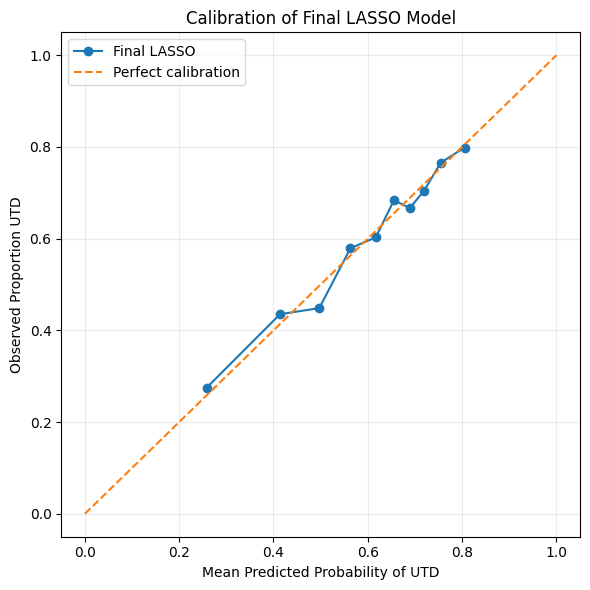

In [ ]:
# ============================================================
# FINAL HELD-OUT TEST PERFORMANCE — LASSO
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.metrics import (
    roc_auc_score,
    accuracy_score,
    balanced_accuracy_score,
    f1_score,
    precision_score,
    recall_score,
    confusion_matrix,
    brier_score_loss
)

from sklearn.calibration import calibration_curve


# ============================================================
# 1. FINAL PREDICTED PROBABILITIES
# ============================================================

# final_model has already been fit on the FULL training set.
# y = 1 means UTD.

test_probs = final_model.predict_proba(X_test)[:, 1]


# ============================================================
# 2. FIXED CLASSIFICATION THRESHOLD
# ============================================================

# Do NOT optimize this threshold using the held-out test set.

THRESHOLD = 0.50

test_pred = (
    test_probs >= THRESHOLD
).astype(int)


# ============================================================
# 3. CONFUSION MATRIX
# ============================================================

# labels=[0,1] ensures:
#
# TN = actually NOT UTD, predicted NOT UTD
# FP = actually NOT UTD, predicted UTD
# FN = actually UTD, predicted NOT UTD
# TP = actually UTD, predicted UTD

cm = confusion_matrix(
    y_test,
    test_pred,
    labels=[0, 1]
)

tn, fp, fn, tp = cm.ravel()


print("========================================")
print("CONFUSION MATRIX")
print("========================================")

print(cm)

print("\nTrue negatives  (TN):", tn)
print("False positives (FP):", fp)
print("False negatives (FN):", fn)
print("True positives  (TP):", tp)


# ============================================================
# 4. FINAL CLASSIFICATION METRICS
# ============================================================

test_auc = roc_auc_score(
    y_test,
    test_probs
)

accuracy = accuracy_score(
    y_test,
    test_pred
)

balanced_accuracy = balanced_accuracy_score(
    y_test,
    test_pred
)

# Binary F1:
# positive class = UTD
binary_f1 = f1_score(
    y_test,
    test_pred,
    pos_label=1
)

# Weighted F1:
# useful for comparison with LazyClassifier screening results
weighted_f1 = f1_score(
    y_test,
    test_pred,
    average="weighted"
)

precision = precision_score(
    y_test,
    test_pred,
    pos_label=1,
    zero_division=0
)

# Since UTD = 1:
# recall for the positive class = sensitivity for UTD
sensitivity = recall_score(
    y_test,
    test_pred,
    pos_label=1,
    zero_division=0
)

# Specificity = ability to correctly identify NOT-UTD adolescents
specificity = (
    tn / (tn + fp)
    if (tn + fp) > 0
    else np.nan
)


# Optional negative predictive value
npv = (
    tn / (tn + fn)
    if (tn + fn) > 0
    else np.nan
)


# ============================================================
# 5. BRIER SCORE
# ============================================================

brier = brier_score_loss(
    y_test,
    test_probs
)


# Null model:
# assign everyone the UTD prevalence observed in TRAINING,
# not the test set.

train_prevalence = np.mean(y_train)

null_probs = np.full(
    shape=len(y_test),
    fill_value=train_prevalence
)

null_brier = brier_score_loss(
    y_test,
    null_probs
)


# ============================================================
# 6. PRINT FINAL RESULTS
# ============================================================

print("\n========================================")
print("FINAL HELD-OUT TEST PERFORMANCE")
print("========================================")

print(f"Test N:                 {len(y_test)}")
print(f"Threshold:              {THRESHOLD:.2f}")

print(f"\nAUROC:                   {test_auc:.4f}")
print(f"Accuracy:                {accuracy:.4f}")
print(f"Balanced Accuracy:       {balanced_accuracy:.4f}")

print(f"\nBinary F1 (UTD=1):       {binary_f1:.4f}")
print(f"Weighted F1:             {weighted_f1:.4f}")

print(f"\nPrecision / PPV:         {precision:.4f}")
print(f"Sensitivity / Recall:    {sensitivity:.4f}")
print(f"Specificity:             {specificity:.4f}")
print(f"Negative Predictive Val: {npv:.4f}")

print(f"\nBrier Score:             {brier:.4f}")
print(f"Null Brier Score:        {null_brier:.4f}")


# ============================================================
# 7. SAVE RESULTS AS A TABLE
# ============================================================

final_metrics = pd.DataFrame({
    "Metric": [
        "AUROC",
        "Accuracy",
        "Balanced Accuracy",
        "Binary F1 (UTD=1)",
        "Weighted F1",
        "Precision",
        "Sensitivity",
        "Specificity",
        "Negative Predictive Value",
        "Brier Score",
        "Null Brier Score"
    ],

    "Value": [
        test_auc,
        accuracy,
        balanced_accuracy,
        binary_f1,
        weighted_f1,
        precision,
        sensitivity,
        specificity,
        npv,
        brier,
        null_brier
    ]
})

print("\n========================================")
print("FINAL METRICS TABLE")
print("========================================")

display(
    final_metrics.style.format({
        "Value": "{:.4f}"
    })
)


# ============================================================
# 8. CONFUSION MATRIX TABLE
# ============================================================

confusion_table = pd.DataFrame(
    cm,
    index=[
        "Actual NOT UTD",
        "Actual UTD"
    ],
    columns=[
        "Predicted NOT UTD",
        "Predicted UTD"
    ]
)

print("\n========================================")
print("CONFUSION MATRIX TABLE")
print("========================================")

display(confusion_table)


# ============================================================
# 9. CALIBRATION CURVE
# ============================================================

prob_true, prob_pred = calibration_curve(
    y_test,
    test_probs,
    n_bins=10,
    strategy="quantile"
)


calibration_table = pd.DataFrame({
    "Mean Predicted Probability": prob_pred,
    "Observed UTD Proportion": prob_true
})

print("\n========================================")
print("CALIBRATION TABLE")
print("========================================")

display(
    calibration_table.style.format(
        "{:.4f}"
    )
)


# ============================================================
# 10. CALIBRATION PLOT
# ============================================================

plt.figure(figsize=(6, 6))

plt.plot(
    prob_pred,
    prob_true,
    marker="o",
    label="Final LASSO"
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    label="Perfect calibration"
)

plt.xlabel("Mean Predicted Probability of UTD")
plt.ylabel("Observed Proportion UTD")
plt.title("Calibration of Final LASSO Model")
plt.legend()
plt.grid(alpha=0.25)
plt.tight_layout()
plt.show()

In [ ]:
# ============================================================
# RISK TIERS — FINAL HELD-OUT TEST SET
# ============================================================

risk_results = pd.DataFrame({
    "pred_prob": test_probs,
    "observed_UTD": y_test
})

def assign_risk_tier(p):
    if p >= 0.80:
        return "Very Low Risk"
    elif p >= 0.70:
        return "Low Risk"
    elif p >= 0.60:
        return "Moderate Risk"
    elif p >= 0.50:
        return "High Risk"
    else:
        return "Very High Risk"

risk_results["Risk Tier"] = risk_results["pred_prob"].apply(assign_risk_tier)

tier_order = [
    "Very Low Risk",
    "Low Risk",
    "Moderate Risk",
    "High Risk",
    "Very High Risk"
]

risk_summary = (
    risk_results
    .groupby("Risk Tier", observed=False)
    .agg(
        N=("observed_UTD", "size"),
        Mean_Predicted_Probability=("pred_prob", "mean"),
        Observed_UTD_Rate=("observed_UTD", "mean")
    )
    .reindex(tier_order)
)

risk_summary["Observed_UTD_Percent"] = (
    risk_summary["Observed_UTD_Rate"] * 100
)

risk_summary["Mean_Predicted_Percent"] = (
    risk_summary["Mean_Predicted_Probability"] * 100
)

print(risk_summary)

                   N  Mean_Predicted_Probability  Observed_UTD_Rate  \
Risk Tier                                                             
Very Low Risk    240                    0.825596           0.804167   
Low Risk        1293                    0.744091           0.744006   
Moderate Risk   1310                    0.654450           0.653435   
High Risk        790                    0.552589           0.534177   
Very High Risk  1233                    0.366618           0.378751   

                Observed_UTD_Percent  Mean_Predicted_Percent  
Risk Tier                                                     
Very Low Risk              80.416667               82.559598  
Low Risk                   74.400619               74.409059  
Moderate Risk              65.343511               65.445027  
High Risk                  53.417722               55.258862  
Very High Risk             37.875101               36.661791  


Total transformed features: 160
LASSO intercept: -0.5328110406450214
LASSO iterations: [23]

All selected features mapped successfully.

LASSO FEATURE SELECTION
Total transformed features: 160
Total non-zero transformed features: 101
Non-zero one-hot features: 99
Non-zero numeric features: 2
Unique original predictors retained: 25

Retained predictors:
['AGE', 'AGEGRP_M_I', 'ASTHMA', 'C1R', 'C5R', 'CHILDNM', 'CKUP_11_12', 'CPOX_HAD', 'EDUC1', 'EDUC_TR', 'FACILITY', 'HPVI_RECOM', 'INCPOV1', 'INS_BREAK_I', 'INS_STAT2_I', 'LANGUAGE', 'MARITAL2', 'MOBIL_I', 'NOSCHOOLR', 'RACEETHK', 'RENT_OWN', 'RISK_HH', 'SEX', 'STATE', 'VISITS']

ALL NON-ZERO LASSO FEATURES


,Predictor,Level,Encoded_Feature,Theme,Coefficient,Abs_Coefficient,Direction,Feature_Type
0,FACILITY,ALL STD/SCHOOL/TEEN CLINICS OR OTHER FACILITIES,FACILITY_ALL STD/SCHOOL/TEEN CLINICS OR OTHER FACILITIES,Healthcare access / delivery,-1.0546,1.0546,Negative,Categorical / one-hot
1,STATE,MISSISSIPPI,STATE_MISSISSIPPI,Geography,-0.9289,0.9289,Negative,Categorical / one-hot
2,HPVI_RECOM,NO,HPVI_RECOM_NO,Healthcare access / delivery,-0.6382,0.6382,Negative,Categorical / one-hot
3,STATE,OKLAHOMA,STATE_OKLAHOMA,Geography,-0.5781,0.5781,Negative,Categorical / one-hot
4,STATE,MASSACHUSETTS,STATE_MASSACHUSETTS,Geography,0.5482,0.5482,Positive,Categorical / one-hot
5,CKUP_11_12,YES,CKUP_11_12_YES,Healthcare access / delivery,0.5386,0.5386,Positive,Categorical / one-hot
6,STATE,MISSOURI,STATE_MISSOURI,Geography,-0.4916,0.4916,Negative,Categorical / one-hot
7,STATE,WYOMING,STATE_WYOMING,Geography,-0.4788,0.4788,Negative,Categorical / one-hot
8,STATE,NORTH DAKOTA,STATE_NORTH DAKOTA,Geography,0.4516,0.4516,Positive,Categorical / one-hot
9,STATE,RHODE ISLAND,STATE_RHODE ISLAND,Geography,0.4450,0.4450,Positive,Categorical / one-hot



REPRESENTATIVE COEFFICIENT PER PREDICTOR


,Predictor,Level,Theme,Coefficient,Abs_Coefficient,Direction
0,FACILITY,ALL STD/SCHOOL/TEEN CLINICS OR OTHER FACILITIES,Healthcare access / delivery,-1.0546,1.0546,Negative
1,STATE,MISSISSIPPI,Geography,-0.9289,0.9289,Negative
2,HPVI_RECOM,NO,Healthcare access / delivery,-0.6382,0.6382,Negative
3,CKUP_11_12,YES,Healthcare access / delivery,0.5386,0.5386,Positive
4,INS_BREAK_I,CURRENTLY INSURED AND NEVER UNINSURED SINCE AGE 11,Healthcare access / delivery,0.4320,0.4320,Positive
5,VISITS,NONE,Healthcare access / delivery,-0.3138,0.3138,Negative
6,LANGUAGE,SPANISH,Household / family,0.2990,0.2990,Positive
7,EDUC1,"MORE THAN 12 YEARS, NON-COLLEGE GRAD",Household / family,-0.2788,0.2788,Negative
8,CPOX_HAD,NO,Health characteristics,0.2787,0.2787,Positive
9,ASTHMA,YES,Health characteristics,0.1928,0.1928,Positive



TOP POSITIVE FEATURES


,Predictor,Level,Theme,Coefficient
4,STATE,MASSACHUSETTS,Geography,0.5482
5,CKUP_11_12,YES,Healthcare access / delivery,0.5386
8,STATE,NORTH DAKOTA,Geography,0.4516
9,STATE,RHODE ISLAND,Geography,0.4450
10,STATE,SOUTH DAKOTA,Geography,0.4403
11,INS_BREAK_I,CURRENTLY INSURED AND NEVER UNINSURED SINCE AGE 11,Healthcare access / delivery,0.4320
13,STATE,NEW HAMPSHIRE,Geography,0.3663
16,STATE,HAWAII,Geography,0.3223
19,LANGUAGE,SPANISH,Household / family,0.2990
21,HPVI_RECOM,YES,Healthcare access / delivery,0.2789



TOP NEGATIVE FEATURES


,Predictor,Level,Theme,Coefficient
0,FACILITY,ALL STD/SCHOOL/TEEN CLINICS OR OTHER FACILITIES,Healthcare access / delivery,-1.0546
1,STATE,MISSISSIPPI,Geography,-0.9289
2,HPVI_RECOM,NO,Healthcare access / delivery,-0.6382
3,STATE,OKLAHOMA,Geography,-0.5781
6,STATE,MISSOURI,Geography,-0.4916
7,STATE,WYOMING,Geography,-0.4788
12,STATE,TENNESSEE,Geography,-0.4290
14,STATE,WEST VIRGINIA,Geography,-0.3655
15,CKUP_11_12,NO,Healthcare access / delivery,-0.3457
17,STATE,TEXAS,Geography,-0.3184



NON-ZERO FEATURES PER PREDICTOR


,Theme,Predictor,Nonzero_Features,Max_Abs_Coefficient
8,Healthcare access / delivery,FACILITY,6,1.0546
3,Geography,STATE,34,0.9289
9,Healthcare access / delivery,HPVI_RECOM,3,0.6382
7,Healthcare access / delivery,CKUP_11_12,2,0.5386
10,Healthcare access / delivery,INS_BREAK_I,2,0.4320
13,Healthcare access / delivery,VISITS,7,0.3138
20,Household / family,LANGUAGE,1,0.2990
18,Household / family,EDUC1,4,0.2788
5,Health characteristics,CPOX_HAD,2,0.2787
4,Health characteristics,ASTHMA,1,0.1928


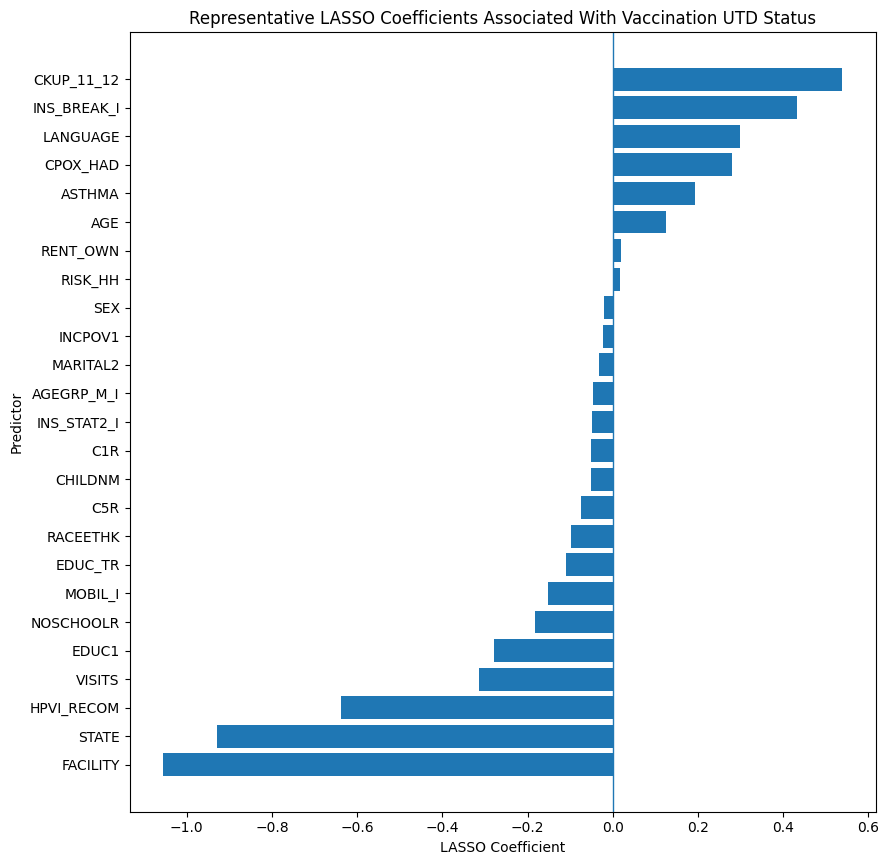


Saved coefficient tables.


In [ ]:
# ============================================================
# FINAL LASSO — SELECTED FEATURES AND COEFFICIENTS
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


# ============================================================
# 1. EXTRACT FITTED PREPROCESSOR AND FINAL LASSO
# ============================================================

fitted_preprocess = final_model.named_steps["preprocess"]
fitted_lasso = final_model.named_steps["model"]

feature_names = fitted_preprocess.get_feature_names_out()
coefficients = fitted_lasso.coef_.ravel()

assert len(feature_names) == len(coefficients), (
    f"Mismatch: {len(feature_names)} transformed features "
    f"but {len(coefficients)} coefficients."
)

print("Total transformed features:", len(feature_names))
print("LASSO intercept:", fitted_lasso.intercept_[0])

# Check convergence
print("LASSO iterations:", fitted_lasso.n_iter_)


# ============================================================
# 2. FULL COEFFICIENT TABLE
# ============================================================

coef_table = pd.DataFrame({
    "Encoded_Feature": feature_names,
    "Coefficient": coefficients
})

coef_table["Abs_Coefficient"] = (
    coef_table["Coefficient"].abs()
)


# ============================================================
# 3. MAP ENCODED FEATURES TO ORIGINAL PREDICTORS
# ============================================================

# Longest names first prevents incorrect matching when
# variable names share prefixes.
cat_sorted = sorted(
    categorical_features,
    key=len,
    reverse=True
)


def identify_source_predictor(feature_name):

    # Numeric predictors are unchanged by StandardScaler
    if feature_name in numeric_features:
        return feature_name

    # OHE features have the form VARIABLE_LEVEL
    for predictor in cat_sorted:
        prefix = predictor + "_"

        if feature_name.startswith(prefix):
            return predictor

    return "UNKNOWN"


coef_table["Predictor"] = (
    coef_table["Encoded_Feature"]
    .apply(identify_source_predictor)
)


# ============================================================
# 4. IDENTIFY FEATURE LEVEL
# ============================================================

def identify_level(row):

    predictor = row["Predictor"]
    feature = row["Encoded_Feature"]

    if predictor in numeric_features:
        return "Continuous"

    prefix = predictor + "_"

    if feature.startswith(prefix):
        return feature[len(prefix):]

    return feature


coef_table["Level"] = coef_table.apply(
    identify_level,
    axis=1
)


coef_table["Feature_Type"] = np.where(
    coef_table["Predictor"].isin(numeric_features),
    "Numeric",
    "Categorical / one-hot"
)


# ============================================================
# 5. RETAIN NON-ZERO LASSO COEFFICIENTS
# ============================================================

ZERO_TOL = 1e-8

selected_features = (
    coef_table.loc[
        coef_table["Abs_Coefficient"] > ZERO_TOL
    ]
    .copy()
)

selected_features["Direction"] = np.where(
    selected_features["Coefficient"] > 0,
    "Positive",
    "Negative"
)

selected_features = (
    selected_features
    .sort_values(
        "Abs_Coefficient",
        ascending=False
    )
    .reset_index(drop=True)
)


# ============================================================
# 6. VERIFY ALL FEATURES MAPPED CORRECTLY
# ============================================================

unknown = selected_features.loc[
    selected_features["Predictor"] == "UNKNOWN"
]

if not unknown.empty:
    print("\nWARNING — unmapped features:")
    display(unknown)
    raise ValueError(
        "Some transformed features could not be mapped "
        "to their original predictors."
    )

print("\nAll selected features mapped successfully.")


# ============================================================
# 7. COUNT SELECTED FEATURES AND ORIGINAL PREDICTORS
# ============================================================

n_nonzero_features = len(selected_features)

n_nonzero_categorical = (
    selected_features["Feature_Type"]
    .eq("Categorical / one-hot")
    .sum()
)

n_nonzero_numeric = (
    selected_features["Feature_Type"]
    .eq("Numeric")
    .sum()
)

n_retained_predictors = (
    selected_features["Predictor"]
    .nunique()
)


print("\n========================================")
print("LASSO FEATURE SELECTION")
print("========================================")

print("Total transformed features:",
      len(coef_table))

print("Total non-zero transformed features:",
      n_nonzero_features)

print("Non-zero one-hot features:",
      n_nonzero_categorical)

print("Non-zero numeric features:",
      n_nonzero_numeric)

print("Unique original predictors retained:",
      n_retained_predictors)

print("\nRetained predictors:")

print(
    sorted(
        selected_features["Predictor"].unique()
    )
)


# ============================================================
# 8. OPTIONAL BROAD CONCEPTUAL GROUPS
# ============================================================

# These are useful for organizing tables/discussion.
# They do NOT determine the representative Figure 2 coefficient.

theme_map = {

    "AGE": "Adolescent characteristics",
    "SEX": "Adolescent characteristics",
    "RACEETHK": "Adolescent characteristics",

    "ASTHMA": "Health characteristics",
    "CPOX_HAD": "Health characteristics",
    "RISK_EVER": "Health characteristics",
    "RISK_HH": "Health characteristics",

    "AGEGRP_M_I": "Household / family",
    "C1R": "Household / family",
    "C5R": "Household / family",
    "CHILDNM": "Household / family",
    "EDUC1": "Household / family",
    "EDUC_TR": "Household / family",
    "MARITAL2": "Household / family",
    "RENT_OWN": "Household / family",
    "LANGUAGE": "Household / family",

    "INCPOV1": "Socioeconomic",

    "VISITS": "Healthcare access / delivery",
    "CKUP_11_12": "Healthcare access / delivery",
    "HPVI_RECOM": "Healthcare access / delivery",
    "NOSCHOOLR": "Healthcare access / delivery",
    "FACILITY": "Healthcare access / delivery",
    "INS_BREAK_I": "Healthcare access / delivery",
    "INS_STAT2_I": "Healthcare access / delivery",

    "MOBIL_I": "Mobility",

    "STATE": "Geography"
}

selected_features["Theme"] = (
    selected_features["Predictor"]
    .map(theme_map)
    .fillna("Other")
)


# ============================================================
# 9. COMPLETE SUPPLEMENTARY FEATURE TABLE
# ============================================================

supplement_selected_features = (
    selected_features[
        [
            "Predictor",
            "Level",
            "Encoded_Feature",
            "Theme",
            "Coefficient",
            "Abs_Coefficient",
            "Direction",
            "Feature_Type"
        ]
    ]
    .copy()
)

print("\n========================================")
print("ALL NON-ZERO LASSO FEATURES")
print("========================================")

display(
    supplement_selected_features.style.format({
        "Coefficient": "{:.4f}",
        "Abs_Coefficient": "{:.4f}"
    })
)


# ============================================================
# 10. REPRESENTATIVE COEFFICIENT FOR EACH ORIGINAL PREDICTOR
# ============================================================

# For each original predictor, choose the selected encoded
# level having the largest absolute coefficient.
#
# Example:
# STATE has many one-hot coefficients.
# The state with the largest |coefficient| represents STATE
# in Figure 2.

representative_idx = (
    selected_features
    .groupby("Predictor")["Abs_Coefficient"]
    .idxmax()
)

predictor_representatives = (
    selected_features
    .loc[representative_idx]
    .copy()
    .sort_values(
        "Abs_Coefficient",
        ascending=False
    )
    .reset_index(drop=True)
)

predictor_representatives = (
    predictor_representatives[
        [
            "Predictor",
            "Level",
            "Theme",
            "Coefficient",
            "Abs_Coefficient",
            "Direction"
        ]
    ]
)


print("\n========================================")
print("REPRESENTATIVE COEFFICIENT PER PREDICTOR")
print("========================================")

display(
    predictor_representatives.style.format({
        "Coefficient": "{:.4f}",
        "Abs_Coefficient": "{:.4f}"
    })
)


# ============================================================
# 11. TOP POSITIVE FEATURES
# ============================================================

top_positive = (
    selected_features.loc[
        selected_features["Coefficient"] > 0
    ]
    .sort_values(
        "Coefficient",
        ascending=False
    )
    .head(20)
)

print("\n========================================")
print("TOP POSITIVE FEATURES")
print("========================================")

display(
    top_positive[
        [
            "Predictor",
            "Level",
            "Theme",
            "Coefficient"
        ]
    ].style.format({
        "Coefficient": "{:.4f}"
    })
)


# ============================================================
# 12. TOP NEGATIVE FEATURES
# ============================================================

top_negative = (
    selected_features.loc[
        selected_features["Coefficient"] < 0
    ]
    .sort_values(
        "Coefficient",
        ascending=True
    )
    .head(20)
)

print("\n========================================")
print("TOP NEGATIVE FEATURES")
print("========================================")

display(
    top_negative[
        [
            "Predictor",
            "Level",
            "Theme",
            "Coefficient"
        ]
    ].style.format({
        "Coefficient": "{:.4f}"
    })
)


# ============================================================
# 13. NUMBER OF NON-ZERO LEVELS PER ORIGINAL PREDICTOR
# ============================================================

selected_per_predictor = (
    selected_features
    .groupby(
        ["Theme", "Predictor"]
    )
    .agg(
        Nonzero_Features=(
            "Encoded_Feature",
            "size"
        ),
        Max_Abs_Coefficient=(
            "Abs_Coefficient",
            "max"
        )
    )
    .reset_index()
    .sort_values(
        "Max_Abs_Coefficient",
        ascending=False
    )
)

print("\n========================================")
print("NON-ZERO FEATURES PER PREDICTOR")
print("========================================")

display(
    selected_per_predictor.style.format({
        "Max_Abs_Coefficient": "{:.4f}"
    })
)


# ============================================================
# 14. FIGURE 2
# One representative coefficient per ORIGINAL predictor
# ============================================================

fig2 = (
    predictor_representatives
    .sort_values(
        "Coefficient",
        ascending=True
    )
    .copy()
)

plt.figure(
    figsize=(
        9,
        max(7, len(fig2) * 0.35)
    )
)

plt.barh(
    fig2["Predictor"],
    fig2["Coefficient"]
)

plt.axvline(
    0,
    linewidth=1
)

plt.xlabel("LASSO Coefficient")
plt.ylabel("Predictor")

plt.title(
    "Representative LASSO Coefficients "
    "Associated With Vaccination UTD Status"
)

plt.tight_layout()
plt.show()


# ============================================================
# 15. SAVE TABLES
# ============================================================

supplement_selected_features.to_csv(
    "2024_LASSO_All_Selected_Features.csv",
    index=False
)

predictor_representatives.to_csv(
    "2024_LASSO_Representative_Predictors.csv",
    index=False
)

selected_per_predictor.to_csv(
    "2024_LASSO_Selected_Features_Per_Predictor.csv",
    index=False
)

print("\nSaved coefficient tables.")

In [ ]:
# ============================================================
# RISK-TIER CHARACTERISTICS / MODEL CONTRIBUTIONS
# For Table 2 and tier-specific Results paragraph
# ============================================================

import numpy as np
import pandas as pd


# ============================================================
# 1. GET FINAL FITTED MODEL COMPONENTS
# ============================================================

fitted_preprocess = final_model.named_steps["preprocess"]
fitted_lasso = final_model.named_steps["model"]

# Raw held-out test data
X_test_raw = test_df[X_cols].copy()
y_test = test_df[y_col].astype(int).values

# Final predicted probabilities
test_probs = final_model.predict_proba(X_test_raw)[:, 1]

# Transform using the already-fitted training preprocessor
X_test_transformed = fitted_preprocess.transform(X_test_raw)

# Convert to dense array if necessary
if hasattr(X_test_transformed, "toarray"):
    X_test_transformed = X_test_transformed.toarray()

feature_names = fitted_preprocess.get_feature_names_out()
coefficients = fitted_lasso.coef_.ravel()
intercept = fitted_lasso.intercept_[0]

assert X_test_transformed.shape[1] == len(coefficients)
assert len(feature_names) == len(coefficients)


# ============================================================
# 2. VERIFY CONTRIBUTIONS RECONSTRUCT MODEL PREDICTIONS
# ============================================================

# Contribution of each transformed feature:
#
# transformed feature value × LASSO coefficient
#
# Contributions are on the LOG-ODDS scale.

contribution_matrix = (
    X_test_transformed * coefficients
)

reconstructed_logit = (
    intercept
    + contribution_matrix.sum(axis=1)
)

actual_logit = final_model.decision_function(X_test_raw)

max_difference = np.max(
    np.abs(reconstructed_logit - actual_logit)
)

print("Maximum logit reconstruction difference:",
      max_difference)

assert max_difference < 1e-6, (
    "Feature contributions do not reconstruct "
    "the final model correctly."
)


# ============================================================
# 3. ASSIGN THE FIVE FIXED RISK TIERS
# ============================================================

risk_tier = pd.cut(
    test_probs,
    bins=[
        -np.inf,
        0.50,
        0.60,
        0.70,
        0.80,
        np.inf
    ],
    labels=[
        "Very High Risk",
        "High Risk",
        "Moderate Risk",
        "Low Risk",
        "Very Low Risk"
    ],
    right=False
)

tier_order = [
    "Very Low Risk",
    "Low Risk",
    "Moderate Risk",
    "High Risk",
    "Very High Risk"
]

risk_tier = pd.Categorical(
    risk_tier,
    categories=tier_order,
    ordered=True
)


# ============================================================
# 4. BASIC TIER SUMMARY
# ============================================================

tier_info = pd.DataFrame({
    "Risk_Tier": risk_tier,
    "Predicted_Probability": test_probs,
    "Observed_UTD": y_test
})

tier_summary = (
    tier_info
    .groupby(
        "Risk_Tier",
        observed=False
    )
    .agg(
        N=("Observed_UTD", "size"),
        Mean_Predicted_Probability=(
            "Predicted_Probability",
            "mean"
        ),
        Observed_UTD_Rate=(
            "Observed_UTD",
            "mean"
        )
    )
    .reindex(tier_order)
)

tier_summary["Mean_Predicted_Percent"] = (
    100 * tier_summary["Mean_Predicted_Probability"]
)

tier_summary["Observed_UTD_Percent"] = (
    100 * tier_summary["Observed_UTD_Rate"]
)

print("\n========================================")
print("RISK TIER SUMMARY")
print("========================================")

display(tier_summary)


# ============================================================
# 5. MAP ENCODED FEATURES BACK TO ORIGINAL PREDICTORS
# ============================================================

cat_sorted = sorted(
    categorical_features,
    key=len,
    reverse=True
)


def identify_source_predictor(feature_name):

    # Numeric predictor
    if feature_name in numeric_features:
        return feature_name

    # One-hot categorical predictor
    for predictor in cat_sorted:
        prefix = predictor + "_"

        if feature_name.startswith(prefix):
            return predictor

    return "UNKNOWN"


def identify_level(feature_name, predictor):

    if predictor in numeric_features:
        return "Continuous"

    prefix = predictor + "_"

    if feature_name.startswith(prefix):
        return feature_name[len(prefix):]

    return feature_name


feature_metadata = pd.DataFrame({
    "Encoded_Feature": feature_names,
    "Coefficient": coefficients
})

feature_metadata["Abs_Coefficient"] = (
    feature_metadata["Coefficient"].abs()
)

feature_metadata["Predictor"] = (
    feature_metadata["Encoded_Feature"]
    .apply(identify_source_predictor)
)

feature_metadata["Level"] = [
    identify_level(feature, predictor)
    for feature, predictor in zip(
        feature_metadata["Encoded_Feature"],
        feature_metadata["Predictor"]
    )
]

feature_metadata["Feature_Type"] = np.where(
    feature_metadata["Predictor"].isin(
        numeric_features
    ),
    "Numeric",
    "Categorical / one-hot"
)


# Fail if mapping went wrong
unknown = feature_metadata[
    feature_metadata["Predictor"] == "UNKNOWN"
]

if not unknown.empty:
    display(unknown)

    raise ValueError(
        "Some transformed features could not "
        "be mapped to original predictors."
    )


# ============================================================
# 6. REMOVE ZERO LASSO FEATURES
# ============================================================

ZERO_TOL = 1e-8

selected_mask = (
    np.abs(coefficients) > ZERO_TOL
)

selected_metadata = (
    feature_metadata.loc[selected_mask]
    .copy()
    .reset_index(drop=True)
)

selected_contributions = (
    contribution_matrix[:, selected_mask]
)

selected_values = (
    X_test_transformed[:, selected_mask]
)

print("\nSelected non-zero transformed features:",
      selected_contributions.shape[1])


# ============================================================
# 7. BUILD INDIVIDUAL-LEVEL CONTRIBUTION DATA
# ============================================================

contribution_df = pd.DataFrame(
    selected_contributions,
    columns=selected_metadata["Encoded_Feature"]
)

contribution_df["Risk_Tier"] = risk_tier


# Also retain the transformed values.
#
# For categorical/OHE variables:
#   mean transformed value = prevalence of that level.
#
# For continuous variables:
#   mean transformed value = mean standardized value.

value_df = pd.DataFrame(
    selected_values,
    columns=selected_metadata["Encoded_Feature"]
)

value_df["Risk_Tier"] = risk_tier


# ============================================================
# 8. FEATURE-LEVEL CONTRIBUTIONS WITHIN EACH TIER
# ============================================================

tier_feature_rows = []

for tier in tier_order:

    tier_mask = (
        contribution_df["Risk_Tier"] == tier
    )

    n_tier = int(tier_mask.sum())

    if n_tier == 0:
        continue

    for j, row in selected_metadata.iterrows():

        feature = row["Encoded_Feature"]
        predictor = row["Predictor"]
        level = row["Level"]
        feature_type = row["Feature_Type"]
        coefficient = row["Coefficient"]

        mean_contribution = (
            contribution_df.loc[
                tier_mask,
                feature
            ].mean()
        )

        mean_feature_value = (
            value_df.loc[
                tier_mask,
                feature
            ].mean()
        )

        # For one-hot variables, this is the proportion of
        # adolescents in the tier with this category.
        if feature_type == "Categorical / one-hot":
            prevalence = mean_feature_value
        else:
            prevalence = np.nan

        tier_feature_rows.append({
            "Risk_Tier": tier,
            "N_Tier": n_tier,
            "Predictor": predictor,
            "Level": level,
            "Encoded_Feature": feature,
            "Feature_Type": feature_type,
            "Coefficient": coefficient,
            "Mean_Contribution": mean_contribution,
            "Abs_Mean_Contribution":
                abs(mean_contribution),
            "Tier_Prevalence":
                prevalence
        })


tier_feature_summary = pd.DataFrame(
    tier_feature_rows
)


# ============================================================
# 9. HUMAN-READABLE FEATURE LABELS
# ============================================================

def make_feature_label(row):

    if row["Feature_Type"] == "Numeric":
        return row["Predictor"]

    return (
        f"{row['Predictor']} = "
        f"{row['Level']}"
    )


tier_feature_summary["Feature_Label"] = (
    tier_feature_summary.apply(
        make_feature_label,
        axis=1
    )
)


# ============================================================
# 10. TOP POSITIVE CONTRIBUTORS WITHIN EACH TIER
# ============================================================

top_positive_by_tier = (
    tier_feature_summary[
        tier_feature_summary[
            "Mean_Contribution"
        ] > 0
    ]
    .sort_values(
        [
            "Risk_Tier",
            "Mean_Contribution"
        ],
        ascending=[True, False]
    )
    .groupby(
        "Risk_Tier",
        observed=False
    )
    .head(8)
)


print("\n========================================")
print("TOP POSITIVE CONTRIBUTORS BY RISK TIER")
print("========================================")

for tier in tier_order:

    print(f"\n--- {tier} ---")

    temp = top_positive_by_tier[
        top_positive_by_tier["Risk_Tier"] == tier
    ]

    display(
        temp[
            [
                "Feature_Label",
                "Coefficient",
                "Tier_Prevalence",
                "Mean_Contribution"
            ]
        ].style.format({
            "Coefficient": "{:.4f}",
            "Tier_Prevalence": "{:.1%}",
            "Mean_Contribution": "{:.4f}"
        })
    )


# ============================================================
# 11. TOP NEGATIVE CONTRIBUTORS WITHIN EACH TIER
# ============================================================

top_negative_by_tier = (
    tier_feature_summary[
        tier_feature_summary[
            "Mean_Contribution"
        ] < 0
    ]
    .sort_values(
        [
            "Risk_Tier",
            "Mean_Contribution"
        ],
        ascending=[True, True]
    )
    .groupby(
        "Risk_Tier",
        observed=False
    )
    .head(8)
)


print("\n========================================")
print("TOP NEGATIVE CONTRIBUTORS BY RISK TIER")
print("========================================")

for tier in tier_order:

    print(f"\n--- {tier} ---")

    temp = top_negative_by_tier[
        top_negative_by_tier["Risk_Tier"] == tier
    ]

    display(
        temp[
            [
                "Feature_Label",
                "Coefficient",
                "Tier_Prevalence",
                "Mean_Contribution"
            ]
        ].style.format({
            "Coefficient": "{:.4f}",
            "Tier_Prevalence": "{:.1%}",
            "Mean_Contribution": "{:.4f}"
        })
    )


# ============================================================
# 12. AGGREGATE ONE-HOT LEVELS BACK TO ORIGINAL PREDICTORS
# ============================================================

# This gives each adolescent ONE contribution per original
# predictor by summing all encoded levels belonging to it.

predictor_names = list(
    dict.fromkeys(
        selected_metadata["Predictor"]
    )
)

predictor_contribution_df = pd.DataFrame(
    index=np.arange(len(X_test_raw))
)


for predictor in predictor_names:

    feature_indices = np.where(
        selected_metadata["Predictor"].values
        == predictor
    )[0]

    predictor_contribution_df[predictor] = (
        selected_contributions[
            :,
            feature_indices
        ].sum(axis=1)
    )


predictor_contribution_df[
    "Risk_Tier"
] = risk_tier


# ============================================================
# 13. MEAN ORIGINAL-PREDICTOR CONTRIBUTIONS BY TIER
# ============================================================

tier_predictor_rows = []

for tier in tier_order:

    tier_mask = (
        predictor_contribution_df[
            "Risk_Tier"
        ] == tier
    )

    for predictor in predictor_names:

        mean_contribution = (
            predictor_contribution_df.loc[
                tier_mask,
                predictor
            ].mean()
        )

        tier_predictor_rows.append({
            "Risk_Tier": tier,
            "Predictor": predictor,
            "Mean_Contribution":
                mean_contribution,
            "Abs_Mean_Contribution":
                abs(mean_contribution)
        })


tier_predictor_summary = pd.DataFrame(
    tier_predictor_rows
)


# ============================================================
# 14. TOP ORIGINAL PREDICTORS WITHIN EACH TIER
# ============================================================

top_predictors_by_tier = (
    tier_predictor_summary
    .sort_values(
        [
            "Risk_Tier",
            "Abs_Mean_Contribution"
        ],
        ascending=[True, False]
    )
    .groupby(
        "Risk_Tier",
        observed=False
    )
    .head(10)
)


print("\n========================================")
print("TOP ORIGINAL PREDICTORS BY RISK TIER")
print("========================================")

for tier in tier_order:

    print(f"\n--- {tier} ---")

    temp = top_predictors_by_tier[
        top_predictors_by_tier[
            "Risk_Tier"
        ] == tier
    ]

    display(
        temp[
            [
                "Predictor",
                "Mean_Contribution",
                "Abs_Mean_Contribution"
            ]
        ].style.format({
            "Mean_Contribution": "{:.4f}",
            "Abs_Mean_Contribution": "{:.4f}"
        })
    )


# ============================================================
# 15. CREATE COMPACT TABLE 2 OUTPUT
# ============================================================

table2_rows = []

TOP_N = 5

for tier in tier_order:

    positive = (
        tier_feature_summary[
            (tier_feature_summary["Risk_Tier"] == tier)
            &
            (tier_feature_summary["Mean_Contribution"] > 0)
        ]
        .nlargest(
            TOP_N,
            "Mean_Contribution"
        )
    )

    negative = (
        tier_feature_summary[
            (tier_feature_summary["Risk_Tier"] == tier)
            &
            (tier_feature_summary["Mean_Contribution"] < 0)
        ]
        .nsmallest(
            TOP_N,
            "Mean_Contribution"
        )
    )

    tier_n = int(
        tier_summary.loc[tier, "N"]
    )

    predicted = (
        tier_summary.loc[
            tier,
            "Mean_Predicted_Percent"
        ]
    )

    observed = (
        tier_summary.loc[
            tier,
            "Observed_UTD_Percent"
        ]
    )

    table2_rows.append({
        "Risk Tier": tier,
        "N": tier_n,
        "Mean Predicted UTD (%)":
            predicted,
        "Observed UTD (%)":
            observed,

        "Top Positive Contributors":
            "; ".join(
                positive[
                    "Feature_Label"
                ].tolist()
            ),

        "Top Negative Contributors":
            "; ".join(
                negative[
                    "Feature_Label"
                ].tolist()
            )
    })


table2 = pd.DataFrame(
    table2_rows
)


print("\n========================================")
print("TABLE 2 — RISK TIER CHARACTERISTICS")
print("========================================")

display(
    table2.style.format({
        "Mean Predicted UTD (%)": "{:.1f}",
        "Observed UTD (%)": "{:.1f}"
    })
)


# ============================================================
# 16. SAVE DETAILED OUTPUTS
# ============================================================

tier_feature_summary.to_csv(
    "2024_RiskTier_Feature_Contributions.csv",
    index=False
)

tier_predictor_summary.to_csv(
    "2024_RiskTier_Predictor_Contributions.csv",
    index=False
)

table2.to_csv(
    "2024_RiskTier_Table2.csv",
    index=False
)


print("\nSaved:")
print("2024_RiskTier_Feature_Contributions.csv")
print("2024_RiskTier_Predictor_Contributions.csv")
print("2024_RiskTier_Table2.csv")

Maximum logit reconstruction difference: 8.881784197001252e-16

RISK TIER SUMMARY


,N,Mean_Predicted_Probability,Observed_UTD_Rate,Mean_Predicted_Percent,Observed_UTD_Percent
Risk_Tier,,,,,
Very Low Risk,240,0.825596,0.804167,82.559598,80.416667
Low Risk,1293,0.744091,0.744006,74.409059,74.400619
Moderate Risk,1310,0.654450,0.653435,65.445027,65.343511
High Risk,790,0.552589,0.534177,55.258862,53.417722
Very High Risk,1233,0.366618,0.378751,36.661791,37.875101



Selected non-zero transformed features: 101

TOP POSITIVE CONTRIBUTORS BY RISK TIER

--- Very Low Risk ---


,Feature_Label,Coefficient,Tier_Prevalence,Mean_Contribution
41,CKUP_11_12 = YES,0.5386,100.0%,0.5386
30,INS_BREAK_I = CURRENTLY INSURED AND NEVER UNINSURED SINCE AGE 11,0.4320,99.6%,0.4302
45,CPOX_HAD = NO,0.2787,98.3%,0.2740
44,HPVI_RECOM = YES,0.2789,97.1%,0.2708
75,STATE = MASSACHUSETTS,0.5482,21.2%,0.1165
99,AGE,0.1253,nan%,0.0918
32,ASTHMA = YES,0.1928,35.8%,0.0691
63,FACILITY = MIXED,0.1773,37.5%,0.0665



--- Low Risk ---


,Feature_Label,Coefficient,Tier_Prevalence,Mean_Contribution
142,CKUP_11_12 = YES,0.5386,99.2%,0.5344
131,INS_BREAK_I = CURRENTLY INSURED AND NEVER UNINSURED SINCE AGE 11,0.4320,98.8%,0.4270
146,CPOX_HAD = NO,0.2787,97.0%,0.2703
145,HPVI_RECOM = YES,0.2789,93.1%,0.2597
119,EDUC_TR = 9TH TO 12TH GRADE,0.0624,89.0%,0.0555
164,FACILITY = MIXED,0.1773,27.5%,0.0487
200,AGE,0.1253,nan%,0.0442
133,ASTHMA = YES,0.1928,21.4%,0.0413


... (25 outputs left out)

,Predictor,Mean_Contribution,Abs_Mean_Contribution
112,INS_BREAK_I,0.3403,0.3403
115,CKUP_11_12,0.2835,0.2835
116,HPVI_RECOM,-0.2702,0.2702
117,CPOX_HAD,0.2443,0.2443
122,STATE,-0.1574,0.1574
121,FACILITY,-0.1436,0.1436
105,EDUC1,-0.0869,0.0869
114,VISITS,-0.0681,0.0681
101,RACEETHK,-0.0523,0.0523
123,AGE,-0.0508,0.0508



TABLE 2 — RISK TIER CHARACTERISTICS


,Risk Tier,N,Mean Predicted UTD (%),Observed UTD (%),Top Positive Contributors,Top Negative Contributors
0,Very Low Risk,240,82.6,80.4,CKUP_11_12 = YES; INS_BREAK_I = CURRENTLY INSURED AND NEVER UNINSURED SINCE AGE 11; CPOX_HAD = NO; HPVI_RECOM = YES; STATE = MASSACHUSETTS,"C5R = MOTHER (STEP, FOSTER, ADOPTIVE) OR FEMALE GUARDIAN; RACEETHK = NON-HISPANIC WHITE ONLY; INS_STAT2_I = PRIVATE INSURANCE ONLY; CHILDNM = ONE; MOBIL_I = MOVED FROM DIFFERENT STATE"
1,Low Risk,1293,74.4,74.4,CKUP_11_12 = YES; INS_BREAK_I = CURRENTLY INSURED AND NEVER UNINSURED SINCE AGE 11; CPOX_HAD = NO; HPVI_RECOM = YES; EDUC_TR = 9TH TO 12TH GRADE,"RACEETHK = NON-HISPANIC WHITE ONLY; C5R = MOTHER (STEP, FOSTER, ADOPTIVE) OR FEMALE GUARDIAN; EDUC1 = MORE THAN 12 YEARS, NON-COLLEGE GRAD; INS_STAT2_I = PRIVATE INSURANCE ONLY; MOBIL_I = MOVED FROM DIFFERENT STATE"
2,Moderate Risk,1310,65.4,65.3,CKUP_11_12 = YES; INS_BREAK_I = CURRENTLY INSURED AND NEVER UNINSURED SINCE AGE 11; CPOX_HAD = NO; HPVI_RECOM = YES; EDUC_TR = 9TH TO 12TH GRADE,"EDUC1 = MORE THAN 12 YEARS, NON-COLLEGE GRAD; RACEETHK = NON-HISPANIC WHITE ONLY; C5R = MOTHER (STEP, FOSTER, ADOPTIVE) OR FEMALE GUARDIAN; MOBIL_I = MOVED FROM DIFFERENT STATE; VISITS = NONE"
3,High Risk,790,55.3,53.4,CKUP_11_12 = YES; INS_BREAK_I = CURRENTLY INSURED AND NEVER UNINSURED SINCE AGE 11; CPOX_HAD = NO; HPVI_RECOM = YES; EDUC_TR = 9TH TO 12TH GRADE,"HPVI_RECOM = NO; EDUC1 = MORE THAN 12 YEARS, NON-COLLEGE GRAD; RACEETHK = NON-HISPANIC WHITE ONLY; C5R = MOTHER (STEP, FOSTER, ADOPTIVE) OR FEMALE GUARDIAN; MOBIL_I = MOVED FROM DIFFERENT STATE"
4,Very High Risk,1233,36.7,37.9,INS_BREAK_I = CURRENTLY INSURED AND NEVER UNINSURED SINCE AGE 11; CKUP_11_12 = YES; CPOX_HAD = NO; HPVI_RECOM = YES; LANGUAGE = SPANISH,"HPVI_RECOM = NO; FACILITY = ALL STD/SCHOOL/TEEN CLINICS OR OTHER FACILITIES; EDUC1 = MORE THAN 12 YEARS, NON-COLLEGE GRAD; VISITS = NONE; RACEETHK = NON-HISPANIC WHITE ONLY"



Saved:
2024_RiskTier_Feature_Contributions.csv
2024_RiskTier_Predictor_Contributions.csv
2024_RiskTier_Table2.csv


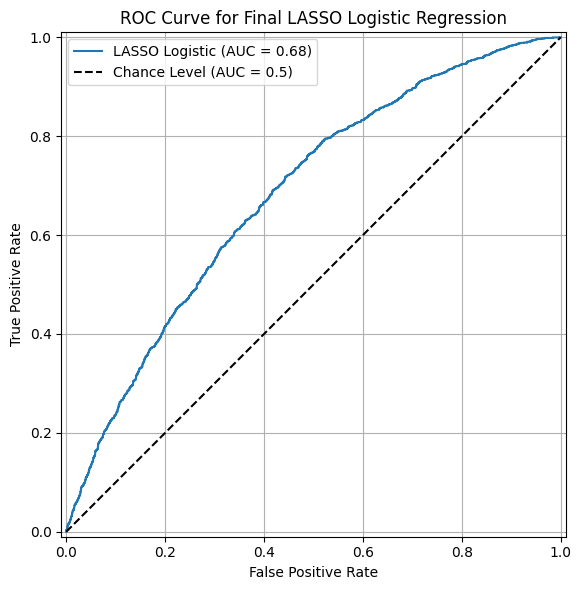


--- Confusion Matrix for Final LASSO Logistic Regression ---
[[ 766 1200]
 [ 467 2433]]


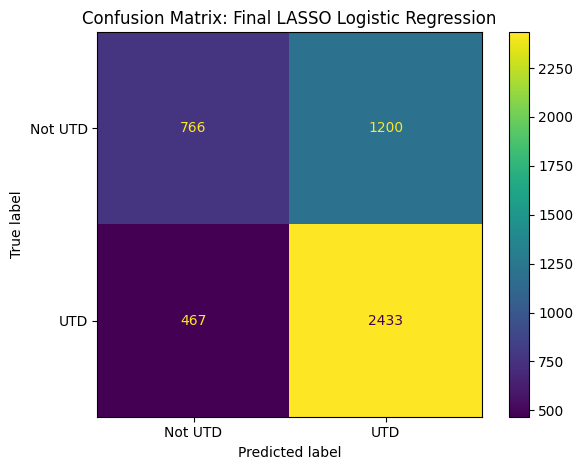


True Negatives: 766
False Positives: 1200
False Negatives: 467
True Positives: 2433

--- Performance Statistics for Final LASSO Logistic Regression ---
ROC AUC:             0.6823
Accuracy:            0.6574
F1 Score:            0.7448
Balanced Accuracy:   0.6143
Precision:           0.6697
Recall/Sensitivity:  0.8390
Specificity:         0.3896

Confusion Matrix Counts:
True Positives:      2433
False Positives:     1200
False Negatives:     467
True Negatives:      766


In [ ]:
# ============================================================
# FINAL LASSO MODEL
# ROC CURVE + CONFUSION MATRIX + PERFORMANCE STATISTICS
# ============================================================

# The classification threshold used for the confusion matrix
# and classification metrics is 0.50, which is the default
# threshold used by LogisticRegression.predict().

import numpy as np
import matplotlib.pyplot as plt

from sklearn.metrics import (
    roc_curve,
    RocCurveDisplay,
    confusion_matrix,
    ConfusionMatrixDisplay,
    roc_auc_score,
    f1_score,
    balanced_accuracy_score,
    accuracy_score,
    precision_score,
    recall_score
)


# ============================================================
# 1. FINAL TEST-SET PREDICTIONS
# ============================================================

# Probability that adolescent is UTD (UTD = 1)
test_probs = final_model.predict_proba(X_test)[:, 1]

# Binary predictions using default 0.50 threshold
test_pred = final_model.predict(X_test)


# ============================================================
# 2. ROC CURVE
# ============================================================

fpr_l1, tpr_l1, thresholds_l1 = roc_curve(
    y_test,
    test_probs
)

roc_auc_l1 = roc_auc_score(
    y_test,
    test_probs
)


plt.figure(figsize=(8, 6))

display_l1 = RocCurveDisplay(
    fpr=fpr_l1,
    tpr=tpr_l1,
    roc_auc=roc_auc_l1,
    estimator_name="LASSO Logistic"
)

display_l1.plot(
    ax=plt.gca()
)

plt.plot(
    [0, 1],
    [0, 1],
    "k--",
    label="Chance Level (AUC = 0.5)"
)

plt.title(
    "ROC Curve for Final LASSO Logistic Regression"
)

plt.xlabel(
    "False Positive Rate"
)

plt.ylabel(
    "True Positive Rate"
)

plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()


# ============================================================
# 3. CONFUSION MATRIX
# ============================================================

cm_l1 = confusion_matrix(
    y_test,
    test_pred,
    labels=[0, 1]
)

print(
    "\n--- Confusion Matrix for Final LASSO Logistic Regression ---"
)

print(cm_l1)


disp_cm = ConfusionMatrixDisplay(
    confusion_matrix=cm_l1,
    display_labels=[
        "Not UTD",
        "UTD"
    ]
)

disp_cm.plot()

plt.title(
    "Confusion Matrix: Final LASSO Logistic Regression"
)

plt.tight_layout()
plt.show()


# ============================================================
# 4. EXTRACT CONFUSION MATRIX VALUES
# ============================================================

# Matrix structure:
#
#                  Predicted
#                 0        1
# Actual 0       TN       FP
# Actual 1       FN       TP
#
# UTD = 1

TN, FP, FN, TP = cm_l1.ravel()


print("\nTrue Negatives:", TN)
print("False Positives:", FP)
print("False Negatives:", FN)
print("True Positives:", TP)


# ============================================================
# 5. PERFORMANCE STATISTICS
# ============================================================

accuracy = accuracy_score(
    y_test,
    test_pred
)

f1 = f1_score(
    y_test,
    test_pred,
    pos_label=1
)

balanced_accuracy = balanced_accuracy_score(
    y_test,
    test_pred
)

precision = precision_score(
    y_test,
    test_pred,
    pos_label=1,
    zero_division=0
)

# Because UTD = 1:
# Recall = sensitivity for identifying UTD adolescents
sensitivity = recall_score(
    y_test,
    test_pred,
    pos_label=1,
    zero_division=0
)

# Specificity = ability to correctly identify NOT-UTD
specificity = (
    TN / (TN + FP)
    if (TN + FP) > 0
    else np.nan
)


# ============================================================
# 6. PRINT PERFORMANCE RESULTS
# ============================================================

print(
    "\n--- Performance Statistics for Final LASSO Logistic Regression ---"
)

print(f"ROC AUC:             {roc_auc_l1:.4f}")
print(f"Accuracy:            {accuracy:.4f}")
print(f"F1 Score:            {f1:.4f}")
print(f"Balanced Accuracy:   {balanced_accuracy:.4f}")
print(f"Precision:           {precision:.4f}")
print(f"Recall/Sensitivity:  {sensitivity:.4f}")
print(f"Specificity:         {specificity:.4f}")

print("\nConfusion Matrix Counts:")
print(f"True Positives:      {TP}")
print(f"False Positives:     {FP}")
print(f"False Negatives:     {FN}")
print(f"True Negatives:      {TN}")

OBSERVED UTD BY RISK TIER


,risk_tier,n,mean_predicted_utd,min_predicted_utd,max_predicted_utd,observed_utd,std_observed_utd,observed_not_utd,pct_pop
0,Very Low,240,82.6%,0.8002,0.9110,80.4%,0.3977,19.6%,4.9%
1,Low,1293,74.4%,0.7002,0.7999,74.4%,0.4366,25.6%,26.6%
2,Moderate,1310,65.4%,0.6000,0.7000,65.3%,0.4761,34.7%,26.9%
3,High,790,55.3%,0.5000,0.6000,53.4%,0.4991,46.6%,16.2%
4,Very High,1233,36.7%,0.0454,0.4999,37.9%,0.4853,62.1%,25.3%



Observed UTD rates:
Very Low: 80.4% (n=240)
Low: 74.4% (n=1293)
Moderate: 65.3% (n=1310)
High: 53.4% (n=790)
Very High: 37.9% (n=1233)


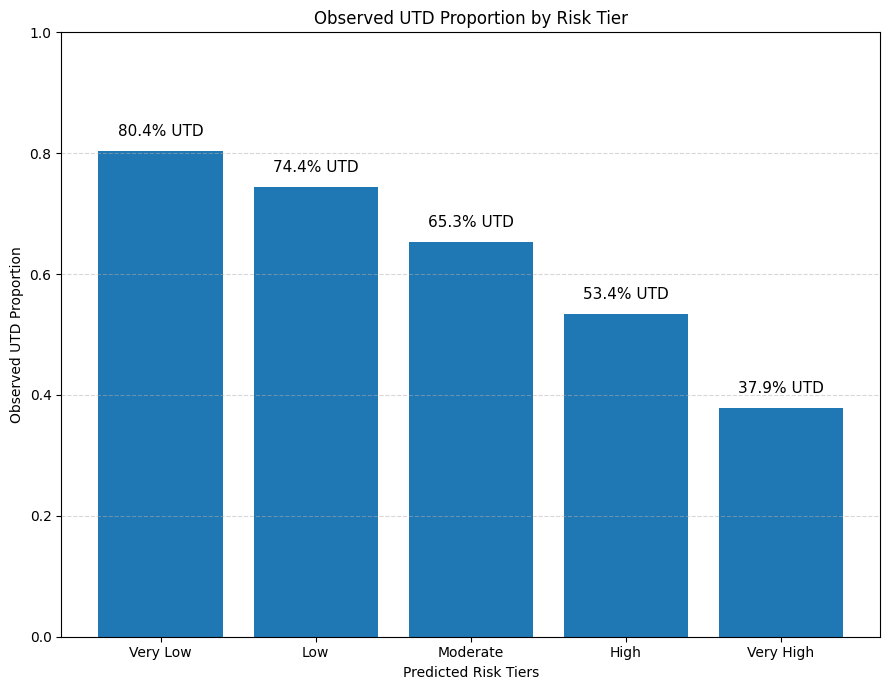

In [ ]:
# ============================================================
# OBSERVED / ACTUAL UTD BY RISK TIER — HELD-OUT TEST SET
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


# ------------------------------------------------------------
# 1. CREATE TEST-SET RISK DATA
# ------------------------------------------------------------

tier_df = test_df.copy()

# Final LASSO predicted probability of being UTD
tier_df["p_hat"] = test_probs


# ------------------------------------------------------------
# 2. ASSIGN FIXED RISK TIERS
# ------------------------------------------------------------

# Lower predicted probability of UTD = higher risk

tier_df["risk_tier"] = pd.cut(
    tier_df["p_hat"],
    bins=[
        -np.inf,
        0.50,
        0.60,
        0.70,
        0.80,
        np.inf
    ],
    labels=[
        "Very High",
        "High",
        "Moderate",
        "Low",
        "Very Low"
    ],
    right=False
)


# Set desired display order
tier_order = [
    "Very Low",
    "Low",
    "Moderate",
    "High",
    "Very High"
]

tier_df["risk_tier"] = pd.Categorical(
    tier_df["risk_tier"],
    categories=tier_order,
    ordered=True
)


# ------------------------------------------------------------
# 3. CREATE TIER SUMMARY TABLE
# ------------------------------------------------------------

tier_table = (
    tier_df
    .groupby(
        "risk_tier",
        observed=False
    )
    .agg(
        n=("risk_tier", "size"),

        # Mean predicted probability of being UTD
        mean_predicted_utd=("p_hat", "mean"),

        min_predicted_utd=("p_hat", "min"),
        max_predicted_utd=("p_hat", "max"),

        # Actual observed UTD rate
        observed_utd=(y_col, "mean"),

        std_observed_utd=(y_col, "std")
    )
    .reset_index()
)


# Observed proportion NOT UTD
tier_table["observed_not_utd"] = (
    1 - tier_table["observed_utd"]
)

# Percentage of test population in each tier
tier_table["pct_pop"] = (
    tier_table["n"]
    / tier_table["n"].sum()
)


# ------------------------------------------------------------
# 4. DISPLAY TABLE
# ------------------------------------------------------------

fmt = {
    "mean_predicted_utd": "{:.1%}",
    "min_predicted_utd": "{:.4f}",
    "max_predicted_utd": "{:.4f}",
    "observed_utd": "{:.1%}",
    "observed_not_utd": "{:.1%}",
    "pct_pop": "{:.1%}",
    "std_observed_utd": "{:.4f}"
}

print("========================================")
print("OBSERVED UTD BY RISK TIER")
print("========================================")

display(
    tier_table.style.format(fmt)
)


# ------------------------------------------------------------
# 5. PRINT OBSERVED UTD RATES
# ------------------------------------------------------------

print("\nObserved UTD rates:")

for _, row in tier_table.iterrows():

    print(
        f"{row['risk_tier']}: "
        f"{row['observed_utd']:.1%} "
        f"(n={int(row['n'])})"
    )


# ============================================================
# 6. BAR GRAPH — OBSERVED UTD PROPORTION BY RISK TIER
# ============================================================

fig, ax = plt.subplots(
    figsize=(9, 7)
)

bars = ax.bar(
    tier_table["risk_tier"].astype(str),
    tier_table["observed_utd"]
)


# Add percentage labels above bars
for bar, observed in zip(
    bars,
    tier_table["observed_utd"]
):

    ax.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 0.02,
        f"{observed * 100:.1f}% UTD",
        ha="center",
        va="bottom",
        fontsize=11
    )


ax.set_ylim(0, 1.0)

ax.set_xlabel(
    "Predicted Risk Tiers"
)

ax.set_ylabel(
    "Observed UTD Proportion"
)

ax.set_title(
    "Observed UTD Proportion by Risk Tier"
)

ax.grid(
    axis="y",
    linestyle="--",
    alpha=0.5
)

plt.tight_layout()
plt.show()

In [ ]:
# ============================================================
# TABLE 1 — 2024 NIS-TEEN
# DESCRIPTIVE CHARACTERISTICS BY COMPOSITE UTD STATUS
#
# Uses FULL national APD cohort (N=16,325)
# NOT the facility-restricted modeling cohort (N=16,217)
# ============================================================

import numpy as np
import pandas as pd
from scipy import stats


# ============================================================
# 1. CREATE DESCRIPTIVE DATASET
# ============================================================

df_table1 = df.copy()

print("Table 1 starting N:", len(df_table1))

assert len(df_table1) == 16325, (
    f"Expected full national APD cohort N=16,325, "
    f"found N={len(df_table1)}."
)

assert y_col in df_table1.columns, (
    f"{y_col} not found."
)


# ============================================================
# 2. ALL CHARACTERISTICS TO INCLUDE
# ============================================================

# This intentionally includes variables that were NOT retained
# by the final LASSO and some variables intentionally excluded
# from the primary model.
#
# Table 1 is descriptive; it is not a list of selected features.

table1_vars = [

    # --------------------------------------------------------
    # Adolescent characteristics
    # --------------------------------------------------------
    "AGE",
    "SEX",

    # Race / ethnicity representations
    "I_HISP_K",
    "RACE_K",
    "RACEETHK",

    # --------------------------------------------------------
    # Household / family characteristics
    # --------------------------------------------------------
    "AGEGRP_M_I",
    "C1R",
    "C5R",
    "CHILDNM",
    "EDUC1",
    "EDUC_TR",
    "MARITAL2",
    "RENT_OWN",
    "LANGUAGE",

    # --------------------------------------------------------
    # Socioeconomic characteristics
    # --------------------------------------------------------
    "INCPORAR_I",
    "INCPOV1",
    "INCQ298A",

    # --------------------------------------------------------
    # Health characteristics
    # --------------------------------------------------------
    "ASTHMA",
    "CPOX_HAD",
    "CPOX_AGE",

    "RISK_EVER",
    "RISK_NOW",
    "RISK_HH",

    # --------------------------------------------------------
    # Healthcare access / preventive care
    # --------------------------------------------------------
    "VISITS",
    "CKUP_11_12",
    "WELLCHILD",
    "HPVI_RECOM",
    "NOSCHOOLR",

    # --------------------------------------------------------
    # Vaccination-history characteristic
    # Descriptive only — NOT used in final model
    # --------------------------------------------------------
    "IMM_ANY",

    # --------------------------------------------------------
    # Provider setting
    # --------------------------------------------------------
    "FACILITY",

    # --------------------------------------------------------
    # Mobility
    # --------------------------------------------------------
    "MOBIL_I",

    # --------------------------------------------------------
    # Geography
    # --------------------------------------------------------
    "CEN_REG",
    "STATE"
]


# Only retain variables actually present in 2024 dataset
available_vars = [
    c for c in table1_vars
    if c in df_table1.columns
]

missing_vars = [
    c for c in table1_vars
    if c not in df_table1.columns
]


print("\nTable 1 variables available:")
print(len(available_vars))
print(available_vars)

if missing_vars:
    print("\nWARNING — requested variables not found:")
    print(missing_vars)


# ============================================================
# 3. HUMAN-READABLE VARIABLE LABELS
# ============================================================

variable_labels = {

    "AGE":
        "Age, years",

    "SEX":
        "Sex",

    "I_HISP_K":
        "Hispanic/Latino ethnicity",

    "RACE_K":
        "Race",

    "RACEETHK":
        "Race/ethnicity",

    "AGEGRP_M_I":
        "Mother's age",

    "C1R":
        "Number of people in household",

    "C5R":
        "Relationship of respondent to adolescent",

    "CHILDNM":
        "Number of children <18 years in household",

    "EDUC1":
        "Mother's education",

    "EDUC_TR":
        "Adolescent's current grade",

    "MARITAL2":
        "Mother's marital status",

    "RENT_OWN":
        "Home ownership status",

    "LANGUAGE":
        "Interview language",

    "INCPORAR_I":
        "Income-to-poverty ratio",

    "INCPOV1":
        "Poverty status",

    "INCQ298A":
        "Family income",

    "INS_BREAK_I":
        "Continuity of insurance coverage since age 11",

    "INS_STAT2_I":
        "Insurance status",

    "ASTHMA":
        "History of asthma",

    "CPOX_HAD":
        "History of chickenpox disease",

    "CPOX_AGE":
        "Age at chickenpox disease",

    "RISK_EVER":
        "History of high-risk health condition",

    "RISK_NOW":
        "Current high-risk health condition",

    "RISK_HH":
        "High-risk health condition in household",

    "VISITS":
        "Healthcare visits in past 12 months",

    "CKUP_11_12":
        "11–12-year preventive checkup",

    "WELLCHILD":
        "Provider-reported 11–12-year well-child visit",

    "HPVI_RECOM":
        "Provider recommendation for HPV vaccination",

    "NOSCHOOLR":
        "School days missed because of illness/injury",

    "IMM_ANY":
        "Household report of any prior vaccination",

    "FACILITY":
        "Vaccination provider facility type",

    "MOBIL_I":
        "Interstate residential mobility",

    "CEN_REG":
        "Census region",

    "STATE":
        "State of residence"
}


# ============================================================
# 4. HANDLE STRUCTURAL FACILITY MISSINGNESS FOR DISPLAY
# ============================================================

# We KNOW from the 2024 data:
#
# FACILITY missing = N_PRVR == 0
#
# N = 108
#
# Keep these adolescents in Table 1, but label the facility
# status accurately rather than calling this an ordinary
# facility category.

if (
    "FACILITY" in df_table1.columns
    and "N_PRVR" in df_table1.columns
):

    fac = df_table1["FACILITY"].astype("string")

    fac_missing = (
        df_table1["FACILITY"].isna()
        |
        fac.str.strip().str.upper().isin(
            ["MISSING", "NAN", "<NA>", ""]
        )
    )

    nprvr = pd.to_numeric(
        df_table1["N_PRVR"],
        errors="coerce"
    )

    # Confirm exact relationship before relabeling
    assert (
        fac_missing == nprvr.eq(0)
    ).all(), (
        "FACILITY missingness no longer corresponds exactly "
        "to N_PRVR=0."
    )

    # Convert to ordinary object/string representation
    df_table1["FACILITY"] = (
        df_table1["FACILITY"]
        .astype("object")
    )

    df_table1.loc[
        fac_missing,
        "FACILITY"
    ] = "Structurally unavailable (N_PRVR=0)"

    print(
        "\nFACILITY structurally unavailable:",
        int(fac_missing.sum())
    )


# ============================================================
# 5. VARIABLE TYPES FOR TABLE 1
# ============================================================

# Treat only genuinely continuous measurements as numeric.
#
# C1R and CHILDNM are recoded count categories, so they are
# displayed categorically here.

numeric_vars = [
    c for c in [
        "AGE",
        "INCPORAR_I",
        "CPOX_AGE"
    ]
    if c in available_vars
]

categorical_vars = [
    c for c in available_vars
    if c not in numeric_vars
]


print("\nNumeric variables:")
print(numeric_vars)

print("\nCategorical variables:")
print(categorical_vars)


# ============================================================
# 6. CLEAN CATEGORY LABELS
# ============================================================

def clean_category_series(series):
    """
    Preserve CDC categorical labels while converting actual
    pandas missing values to the display label 'Missing'.
    """

    s = series.astype("string")

    s = s.str.strip()

    s = s.fillna("Missing")

    # Standardize pandas/string representations of missingness
    s = s.replace({
        "<NA>": "Missing",
        "nan": "Missing",
        "NaN": "Missing",
        "NAN": "Missing",
        "": "Missing"
    })

    return s


# ============================================================
# 7. MISSING/RESERVE CATEGORIES TO EXCLUDE FROM P-VALUE TESTS
# ============================================================

# These categories remain DISPLAYED in Table 1.
#
# They are simply not treated as substantive categories in the
# chi-square comparison.

NON_SUBSTANTIVE_LEVELS = {
    "MISSING",
    "MISSING/UNKNOWN",
    "DON'T KNOW",
    "DONT KNOW",
    "REFUSED",
    "Missing".upper(),
    "STRUCTURALLY UNAVAILABLE (N_PRVR=0)"
}


def is_substantive_level(x):

    x = str(x).strip().upper()

    return x not in NON_SUBSTANTIVE_LEVELS


# ============================================================
# 8. FORMAT P-VALUES
# ============================================================

def format_pvalue(p):

    if pd.isna(p):
        return ""

    if p < 0.001:
        return "<0.001"

    return f"{p:.3f}"


# ============================================================
# 9. NUMERIC VARIABLE SUMMARY
# ============================================================

def summarize_numeric_variable(data, variable, outcome):

    overall = pd.to_numeric(
        data[variable],
        errors="coerce"
    )

    utd = pd.to_numeric(
        data.loc[
            data[outcome] == 1,
            variable
        ],
        errors="coerce"
    )

    not_utd = pd.to_numeric(
        data.loc[
            data[outcome] == 0,
            variable
        ],
        errors="coerce"
    )


    # Remove missing observations only for summaries/test
    overall_valid = overall.dropna()
    utd_valid = utd.dropna()
    not_utd_valid = not_utd.dropna()


    # Welch's two-sample t-test
    if (
        len(utd_valid) > 1
        and len(not_utd_valid) > 1
    ):

        _, p_value = stats.ttest_ind(
            utd_valid,
            not_utd_valid,
            equal_var=False,
            nan_policy="omit"
        )

    else:

        p_value = np.nan


    # Mean ± SD
    overall_text = (
        f"{overall_valid.mean():.2f} ± "
        f"{overall_valid.std():.2f}"
    )

    utd_text = (
        f"{utd_valid.mean():.2f} ± "
        f"{utd_valid.std():.2f}"
    )

    not_utd_text = (
        f"{not_utd_valid.mean():.2f} ± "
        f"{not_utd_valid.std():.2f}"
    )


    rows = [{
        "Variable":
            variable_labels.get(
                variable,
                variable
            ),

        "Variable_Code":
            variable,

        "Level":
            "Mean ± SD",

        "Overall":
            overall_text,

        "UTD":
            utd_text,

        "Not UTD":
            not_utd_text,

        "P-value":
            format_pvalue(p_value),

        "P-value_numeric":
            p_value
    }]


    # Add missing-data row when applicable
    n_missing = overall.isna().sum()

    if n_missing > 0:

        n_total = len(data)

        utd_missing = utd.isna().sum()
        not_utd_missing = not_utd.isna().sum()

        n_utd = (data[outcome] == 1).sum()
        n_not_utd = (data[outcome] == 0).sum()

        rows.append({

            "Variable":
                "",

            "Variable_Code":
                variable,

            "Level":
                "Missing",

            "Overall":
                f"{n_missing:,} "
                f"({100*n_missing/n_total:.1f}%)",

            "UTD":
                f"{utd_missing:,} "
                f"({100*utd_missing/n_utd:.1f}%)",

            "Not UTD":
                f"{not_utd_missing:,} "
                f"({100*not_utd_missing/n_not_utd:.1f}%)",

            "P-value":
                "",

            "P-value_numeric":
                np.nan
        })


    return rows


# ============================================================
# 10. CATEGORICAL VARIABLE SUMMARY
# ============================================================

def summarize_categorical_variable(
    data,
    variable,
    outcome
):

    temp = pd.DataFrame({
        "category":
            clean_category_series(
                data[variable]
            ),
        "outcome":
            data[outcome].astype(int)
    })


    # --------------------------------------------------------
    # P-value
    # --------------------------------------------------------

    # Remove reserve/missing categories from hypothesis test.
    #
    # They remain visible in the descriptive table.

    test_temp = temp.loc[
        temp["category"].apply(
            is_substantive_level
        )
    ].copy()


    contingency = pd.crosstab(
        test_temp["category"],
        test_temp["outcome"]
    )


    p_value = np.nan


    if (
        contingency.shape[0] > 1
        and contingency.shape[1] == 2
    ):

        try:

            chi2, p_value, dof, expected = (
                stats.chi2_contingency(
                    contingency
                )
            )

        except ValueError:

            p_value = np.nan


    # --------------------------------------------------------
    # Column denominators
    # --------------------------------------------------------

    n_total = len(temp)

    n_utd = (
        temp["outcome"] == 1
    ).sum()

    n_not_utd = (
        temp["outcome"] == 0
    ).sum()


    # --------------------------------------------------------
    # Preserve useful category ordering
    # --------------------------------------------------------

    category_counts = (
        temp["category"]
        .value_counts(dropna=False)
    )

    levels = list(
        category_counts.index
    )


    rows = []


    for i, level in enumerate(levels):

        overall_n = (
            temp["category"] == level
        ).sum()

        utd_n = (
            (temp["category"] == level)
            &
            (temp["outcome"] == 1)
        ).sum()

        not_utd_n = (
            (temp["category"] == level)
            &
            (temp["outcome"] == 0)
        ).sum()


        rows.append({

            "Variable":
                (
                    variable_labels.get(
                        variable,
                        variable
                    )
                    if i == 0
                    else ""
                ),

            "Variable_Code":
                variable,

            "Level":
                level,

            "Overall":
                (
                    f"{overall_n:,} "
                    f"({100*overall_n/n_total:.1f}%)"
                ),

            "UTD":
                (
                    f"{utd_n:,} "
                    f"({100*utd_n/n_utd:.1f}%)"
                ),

            "Not UTD":
                (
                    f"{not_utd_n:,} "
                    f"({100*not_utd_n/n_not_utd:.1f}%)"
                ),

            # Print p-value only once per variable
            "P-value":
                (
                    format_pvalue(p_value)
                    if i == 0
                    else ""
                ),

            "P-value_numeric":
                (
                    p_value
                    if i == 0
                    else np.nan
                )
        })


    return rows


# ============================================================
# 11. GENERATE COMPLETE TABLE 1
# ============================================================

table1_rows = []


# Preserve exact variable order specified above
for variable in available_vars:

    if variable in numeric_vars:

        rows = summarize_numeric_variable(
            df_table1,
            variable,
            y_col
        )

    else:

        rows = summarize_categorical_variable(
            df_table1,
            variable,
            y_col
        )


    table1_rows.extend(rows)


table1 = pd.DataFrame(
    table1_rows
)


# ============================================================
# 12. FINAL COLUMN ORDER
# ============================================================

table1 = table1[
    [
        "Variable",
        "Variable_Code",
        "Level",
        "Overall",
        "UTD",
        "Not UTD",
        "P-value",
        "P-value_numeric"
    ]
]


# ============================================================
# 13. DISPLAY SAMPLE SIZE
# ============================================================

n_total = len(df_table1)

n_utd = (
    df_table1[y_col] == 1
).sum()

n_not_utd = (
    df_table1[y_col] == 0
).sum()


print("\n========================================")
print("TABLE 1 SAMPLE")
print("========================================")

print(
    f"Overall: N={n_total:,}"
)

print(
    f"UTD: N={n_utd:,} "
    f"({100*n_utd/n_total:.1f}%)"
)

print(
    f"Not UTD: N={n_not_utd:,} "
    f"({100*n_not_utd/n_total:.1f}%)"
)


# ============================================================
# 14. DISPLAY TABLE
# ============================================================

print("\n========================================")
print("TABLE 1")
print("========================================")

display(
    table1[
        [
            "Variable",
            "Level",
            "Overall",
            "UTD",
            "Not UTD",
            "P-value"
        ]
    ]
)


# ============================================================
# 15. SAVE COMPLETE TABLE
# ============================================================

table1.to_csv(
    "2024_NISTeen_Table1_Descriptive_Characteristics.csv",
    index=False
)


# Also save publication-facing version without internal columns

table1_publication = table1[
    [
        "Variable",
        "Level",
        "Overall",
        "UTD",
        "Not UTD",
        "P-value"
    ]
].copy()


table1_publication.to_csv(
    "2024_NISTeen_Table1_Publication.csv",
    index=False
)


print("\nSaved:")
print(
    "2024_NISTeen_Table1_Descriptive_Characteristics.csv"
)

print(
    "2024_NISTeen_Table1_Publication.csv"
)

Table 1 starting N: 16325

Table 1 variables available:
33
['AGE', 'SEX', 'I_HISP_K', 'RACE_K', 'RACEETHK', 'AGEGRP_M_I', 'C1R', 'C5R', 'CHILDNM', 'EDUC1', 'EDUC_TR', 'MARITAL2', 'RENT_OWN', 'LANGUAGE', 'INCPORAR_I', 'INCPOV1', 'INCQ298A', 'ASTHMA', 'CPOX_HAD', 'CPOX_AGE', 'RISK_EVER', 'RISK_NOW', 'RISK_HH', 'VISITS', 'CKUP_11_12', 'WELLCHILD', 'HPVI_RECOM', 'NOSCHOOLR', 'IMM_ANY', 'FACILITY', 'MOBIL_I', 'CEN_REG', 'STATE']

FACILITY structurally unavailable: 108

Numeric variables:
['AGE', 'INCPORAR_I', 'CPOX_AGE']

Categorical variables:
['SEX', 'I_HISP_K', 'RACE_K', 'RACEETHK', 'AGEGRP_M_I', 'C1R', 'C5R', 'CHILDNM', 'EDUC1', 'EDUC_TR', 'MARITAL2', 'RENT_OWN', 'LANGUAGE', 'INCPOV1', 'INCQ298A', 'ASTHMA', 'CPOX_HAD', 'RISK_EVER', 'RISK_NOW', 'RISK_HH', 'VISITS', 'CKUP_11_12', 'WELLCHILD', 'HPVI_RECOM', 'NOSCHOOLR', 'IMM_ANY', 'FACILITY', 'MOBIL_I', 'CEN_REG', 'STATE']

TABLE 1 SAMPLE
Overall: N=16,325
UTD: N=9,664 (59.2%)
Not UTD: N=6,661 (40.8%)

TABLE 1


,Variable,Level,Overall,UTD,Not UTD,P-value
0,"Age, years",Mean ± SD,15.00 ± 1.40,15.13 ± 1.37,14.81 ± 1.42,<0.001
1,Sex,MALE,"8,618 (52.8%)","5,020 (51.9%)","3,598 (54.0%)",0.010
2,,FEMALE,"7,707 (47.2%)","4,644 (48.1%)","3,063 (46.0%)",
3,Hispanic/Latino ethnicity,NO,"12,808 (78.5%)","7,600 (78.6%)","5,208 (78.2%)",0.498
4,,YES,"3,517 (21.5%)","2,064 (21.4%)","1,453 (21.8%)",
...,...,...,...,...,...,...
191,,IOWA,198 (1.2%),116 (1.2%),82 (1.2%),
192,,NORTH DAKOTA,197 (1.2%),135 (1.4%),62 (0.9%),
193,,IDAHO,173 (1.1%),96 (1.0%),77 (1.2%),
194,,CONNECTICUT,166 (1.0%),111 (1.1%),55 (0.8%),



Saved:
2024_NISTeen_Table1_Descriptive_Characteristics.csv
2024_NISTeen_Table1_Publication.csv


In [ ]:
# ============================================================
# 2024 LASSO — BOOTSTRAP COEFFICIENT INTERVALS
#
# 1,000 nonparametric bootstrap samples of TRAINING DATA ONLY
# Final model specification is FIXED:
#   penalty = L1
#   C = Optuna-selected C
#
# Output:
#   - Final coefficient
#   - Mean bootstrap coefficient
#   - Empirical 95% bootstrap interval
#   - Selection frequency across bootstrap samples
# ============================================================

import numpy as np
import pandas as pd
import warnings

from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.exceptions import ConvergenceWarning


# ============================================================
# 1. SETTINGS
# ============================================================

N_BOOTSTRAPS = 1000
BOOTSTRAP_SEED = 2024
ZERO_TOL = 1e-8

# Use the already-selected LASSO C
selected_C = study_l1.best_params["C"]

print("Selected LASSO C:", selected_C)
print("Number of bootstrap samples:", N_BOOTSTRAPS)


# ============================================================
# 2. TRAINING DATA ONLY
# ============================================================

X_boot_source = train_df[X_cols].copy()
y_boot_source = train_df[y_col].astype(int).to_numpy()

n_train = len(X_boot_source)

print("Bootstrap source N:", n_train)

assert n_train == 11351, (
    f"Expected training N=11,351, found {n_train}"
)


# ============================================================
# 3. GET FINAL MODEL FEATURE SPACE
# ============================================================

final_preprocess = final_model.named_steps["preprocess"]
final_lasso = final_model.named_steps["model"]

master_feature_names = (
    final_preprocess.get_feature_names_out()
)

final_coefficients = (
    final_lasso.coef_.ravel()
)

assert (
    len(master_feature_names)
    == len(final_coefficients)
)

print(
    "Number of transformed features:",
    len(master_feature_names)
)


# ============================================================
# 4. FREEZE CATEGORICAL LEVELS
# ============================================================

# We keep the categorical feature space fixed to the levels
# learned from the full TRAINING set.
#
# Numeric medians/scaling are still re-estimated separately
# within every bootstrap sample.

final_cat_pipeline = (
    final_preprocess
    .named_transformers_["cat"]
)

final_ohe = (
    final_cat_pipeline
    .named_steps["onehot"]
)

frozen_categories = [
    np.asarray(cat, dtype=object)
    for cat in final_ohe.categories_
]


# ============================================================
# 5. FUNCTION TO CREATE FRESH PREPROCESSOR
# ============================================================

def make_bootstrap_preprocessor():

    cat_pipeline = Pipeline(
        steps=[
            (
                "imputer",
                SimpleImputer(
                    strategy="constant",
                    fill_value="__MISSING__"
                )
            ),
            (
                "onehot",
                OneHotEncoder(
                    categories=frozen_categories,
                    handle_unknown="ignore",
                    drop=None,
                    sparse_output=False
                )
            )
        ]
    )

    num_pipeline = Pipeline(
        steps=[
            (
                "imputer",
                SimpleImputer(
                    strategy="median"
                )
            ),
            (
                "scaler",
                StandardScaler()
            )
        ]
    )

    return ColumnTransformer(
        transformers=[
            (
                "cat",
                cat_pipeline,
                categorical_features
            ),
            (
                "num",
                num_pipeline,
                numeric_features
            )
        ],
        remainder="drop",
        verbose_feature_names_out=False
    )


# ============================================================
# 6. STORAGE FOR BOOTSTRAP COEFFICIENTS
# ============================================================

bootstrap_coefs = np.zeros(
    (
        N_BOOTSTRAPS,
        len(master_feature_names)
    ),
    dtype=float
)

bootstrap_iterations = np.zeros(
    N_BOOTSTRAPS,
    dtype=int
)


# ============================================================
# 7. GENERATE BOOTSTRAP SAMPLES
# ============================================================

rng = np.random.default_rng(
    BOOTSTRAP_SEED
)

warnings.simplefilter(
    "ignore",
    ConvergenceWarning
)


print("\n========================================")
print("STARTING BOOTSTRAP")
print("========================================")


for b in range(N_BOOTSTRAPS):

    # --------------------------------------------------------
    # Resample TRAINING observations with replacement
    # --------------------------------------------------------

    sample_idx = rng.integers(
        low=0,
        high=n_train,
        size=n_train
    )

    X_b = (
        X_boot_source
        .iloc[sample_idx]
        .reset_index(drop=True)
    )

    y_b = y_boot_source[
        sample_idx
    ]


    # Extremely unlikely with this sample size,
    # but protect against one-class samples.
    if np.unique(y_b).size < 2:
        raise RuntimeError(
            f"Bootstrap {b} contained only one outcome class."
        )


    # --------------------------------------------------------
    # Fresh preprocessing + same final LASSO specification
    # --------------------------------------------------------

    boot_model = Pipeline(
        steps=[
            (
                "preprocess",
                make_bootstrap_preprocessor()
            ),
            (
                "model",
                LogisticRegression(
                    penalty="l1",
                    solver="saga",
                    C=selected_C,
                    class_weight=None,
                    max_iter=5000,
                    random_state=RANDOM_STATE
                )
            )
        ]
    )


    # --------------------------------------------------------
    # Fit bootstrap model
    # --------------------------------------------------------

    boot_model.fit(
        X_b,
        y_b
    )


    # --------------------------------------------------------
    # Extract coefficients
    # --------------------------------------------------------

    boot_feature_names = (
        boot_model
        .named_steps["preprocess"]
        .get_feature_names_out()
    )

    boot_coef = (
        boot_model
        .named_steps["model"]
        .coef_
        .ravel()
    )


    # Fixed categories should guarantee identical feature space
    if not np.array_equal(
        boot_feature_names,
        master_feature_names
    ):
        raise RuntimeError(
            "Bootstrap feature names do not match "
            "the final model feature space."
        )


    bootstrap_coefs[
        b, :
    ] = boot_coef


    bootstrap_iterations[b] = int(
        boot_model
        .named_steps["model"]
        .n_iter_[0]
    )


    # Progress report
    if (
        (b + 1) % 50 == 0
        or b == 0
    ):

        print(
            f"Completed "
            f"{b + 1}/{N_BOOTSTRAPS} "
            f"bootstrap samples"
        )


print("\nBootstrap complete.")


# ============================================================
# 8. CHECK CONVERGENCE
# ============================================================

print("\n========================================")
print("BOOTSTRAP CONVERGENCE")
print("========================================")

print(
    "Maximum iterations used:",
    bootstrap_iterations.max()
)

print(
    "Median iterations:",
    np.median(
        bootstrap_iterations
    )
)

print(
    "Models reaching max_iter:",
    np.sum(
        bootstrap_iterations >= 5000
    )
)


# ============================================================
# 9. CALCULATE BOOTSTRAP STATISTICS
# ============================================================

bootstrap_mean = np.mean(
    bootstrap_coefs,
    axis=0
)

bootstrap_median = np.median(
    bootstrap_coefs,
    axis=0
)

ci_lower = np.percentile(
    bootstrap_coefs,
    2.5,
    axis=0
)

ci_upper = np.percentile(
    bootstrap_coefs,
    97.5,
    axis=0
)

selection_frequency = np.mean(
    np.abs(bootstrap_coefs)
    > ZERO_TOL,
    axis=0
)


# ============================================================
# 10. MAP FEATURES BACK TO ORIGINAL PREDICTORS
# ============================================================

cat_sorted = sorted(
    categorical_features,
    key=len,
    reverse=True
)


def identify_source_predictor(
    feature_name
):

    if feature_name in numeric_features:
        return feature_name

    for predictor in cat_sorted:

        prefix = predictor + "_"

        if feature_name.startswith(
            prefix
        ):
            return predictor

    return "UNKNOWN"


def identify_level(
    feature_name,
    predictor
):

    if predictor in numeric_features:
        return "Continuous"

    prefix = predictor + "_"

    if feature_name.startswith(
        prefix
    ):
        return feature_name[
            len(prefix):
        ]

    return feature_name


predictor_names = [
    identify_source_predictor(x)
    for x in master_feature_names
]

levels = [
    identify_level(
        feature,
        predictor
    )
    for feature, predictor in zip(
        master_feature_names,
        predictor_names
    )
]


# ============================================================
# 11. PREDICTOR THEMES
# ============================================================

theme_map = {

    "AGE":
        "Demographics",

    "SEX":
        "Demographics",

    "RACEETHK":
        "Race / ethnicity",

    "ASTHMA":
        "Chronic health condition",

    "CPOX_HAD":
        "Chronic health condition",

    "RISK_EVER":
        "Chronic health condition",

    "RISK_HH":
        "Chronic health condition",

    "AGEGRP_M_I":
        "Demographics",

    "C1R":
        "Household composition",

    "C5R":
        "Respondent relationship",

    "CHILDNM":
        "Household composition",

    "EDUC1":
        "Socioeconomic status",

    "EDUC_TR":
        "Demographics",

    "MARITAL2":
        "Socioeconomic status",

    "RENT_OWN":
        "Socioeconomic status",

    "LANGUAGE":
        "Language / interview context",

    "INCPOV1":
        "Socioeconomic status",

    "VISITS":
        "Healthcare utilization",

    "INS_BREAK_I":
        "Healthcare utilization",

    "INS_STAT2_I":
        "Healthcare utilization",

    "CKUP_11_12":
        "Preventive care",

    "HPVI_RECOM":
        "Provider HPV recommendation",

    "NOSCHOOLR":
        "School absence due to illness",

    "FACILITY":
        "Facility type / site of care",

    "MOBIL_I":
        "Residential mobility",

    "STATE":
        "Geography - state variation"
}


themes = [
    theme_map.get(
        p,
        "Other"
    )
    for p in predictor_names
]


# ============================================================
# 12. CREATE COMPLETE BOOTSTRAP TABLE
# ============================================================

bootstrap_table = pd.DataFrame({

    "Predictor theme":
        themes,

    "Predictor":
        predictor_names,

    "Level":
        levels,

    "Encoded Feature":
        master_feature_names,

    "Final Coefficient":
        final_coefficients,

    "Mean Bootstrap Coefficient":
        bootstrap_mean,

    "Median Bootstrap Coefficient":
        bootstrap_median,

    "95% Bootstrap Interval - Lower":
        ci_lower,

    "95% Bootstrap Interval - Upper":
        ci_upper,

    "Bootstrap Selection Frequency":
        selection_frequency
})


bootstrap_table[
    "Abs Final Coefficient"
] = np.abs(
    bootstrap_table[
        "Final Coefficient"
    ]
)


# ============================================================
# 13. FLAG WHETHER FINAL LASSO SELECTED FEATURE
# ============================================================

bootstrap_table[
    "Selected in Final Model"
] = (
    bootstrap_table[
        "Abs Final Coefficient"
    ] > ZERO_TOL
)


# Does empirical interval exclude zero?
bootstrap_table[
    "Bootstrap Interval Excludes Zero"
] = (
    (
        bootstrap_table[
            "95% Bootstrap Interval - Lower"
        ] > 0
    )
    |
    (
        bootstrap_table[
            "95% Bootstrap Interval - Upper"
        ] < 0
    )
)


# ============================================================
# 14. SORT TABLE
# ============================================================

# Selected features first, strongest final coefficient first.

bootstrap_table = (
    bootstrap_table
    .sort_values(
        [
            "Selected in Final Model",
            "Abs Final Coefficient"
        ],
        ascending=[
            False,
            False
        ]
    )
    .reset_index(drop=True)
)


# ============================================================
# 15. DISPLAY FINAL-SELECTED FEATURES
# ============================================================

selected_bootstrap_table = (
    bootstrap_table.loc[
        bootstrap_table[
            "Selected in Final Model"
        ]
    ]
    .copy()
)


print("\n========================================")
print("BOOTSTRAP RESULTS — FINAL SELECTED FEATURES")
print("========================================")

print(
    "Selected transformed features:",
    len(selected_bootstrap_table)
)

display(
    selected_bootstrap_table[
        [
            "Predictor theme",
            "Predictor",
            "Level",
            "Final Coefficient",
            "Mean Bootstrap Coefficient",
            "95% Bootstrap Interval - Lower",
            "95% Bootstrap Interval - Upper",
            "Bootstrap Selection Frequency"
        ]
    ].style.format({

        "Final Coefficient":
            "{:.3f}",

        "Mean Bootstrap Coefficient":
            "{:.3f}",

        "95% Bootstrap Interval - Lower":
            "{:.3f}",

        "95% Bootstrap Interval - Upper":
            "{:.3f}",

        "Bootstrap Selection Frequency":
            "{:.1%}"
    })
)


# ============================================================
# 16. STRONGEST BOOTSTRAP-STABLE FEATURES
# ============================================================

stable_features = (
    selected_bootstrap_table.loc[
        selected_bootstrap_table[
            "Bootstrap Selection Frequency"
        ] >= 0.80
    ]
    .copy()
)


print("\n========================================")
print("FEATURES SELECTED IN >=80% OF BOOTSTRAPS")
print("========================================")

display(
    stable_features[
        [
            "Predictor theme",
            "Predictor",
            "Level",
            "Final Coefficient",
            "Mean Bootstrap Coefficient",
            "95% Bootstrap Interval - Lower",
            "95% Bootstrap Interval - Upper",
            "Bootstrap Selection Frequency"
        ]
    ].style.format({

        "Final Coefficient":
            "{:.3f}",

        "Mean Bootstrap Coefficient":
            "{:.3f}",

        "95% Bootstrap Interval - Lower":
            "{:.3f}",

        "95% Bootstrap Interval - Upper":
            "{:.3f}",

        "Bootstrap Selection Frequency":
            "{:.1%}"
    })
)


# ============================================================
# 17. SAVE TABLES
# ============================================================

bootstrap_table.to_csv(
    "2024_LASSO_All_Features_Bootstrap_Intervals.csv",
    index=False
)

selected_bootstrap_table.to_csv(
    "2024_LASSO_Selected_Features_Bootstrap_Intervals.csv",
    index=False
)

stable_features.to_csv(
    "2024_LASSO_Stable_Features_Bootstrap_Intervals.csv",
    index=False
)


print("\nSaved:")
print(
    "2024_LASSO_All_Features_Bootstrap_Intervals.csv"
)
print(
    "2024_LASSO_Selected_Features_Bootstrap_Intervals.csv"
)
print(
    "2024_LASSO_Stable_Features_Bootstrap_Intervals.csv"
)

Selected LASSO C: 0.2348060869554075
Number of bootstrap samples: 1000
Bootstrap source N: 11351
Number of transformed features: 160

STARTING BOOTSTRAP
Completed 1/1000 bootstrap samples


In [ ]:
# ============================================================
# 2024 STATE-LEVEL OBSERVED UTD RATES
# For geographic map / Figure
#
# Uses full national APD cohort: N = 16,325
# UTD = 1 means UTD for BOTH:
#   1:3:2:1:2 series + HPV series
# ============================================================

import pandas as pd
import numpy as np


# ------------------------------------------------------------
# 1. USE FULL NATIONAL DESCRIPTIVE COHORT
# ------------------------------------------------------------

state_df = df.copy()

assert len(state_df) == 16325, (
    f"Expected national cohort N=16,325, "
    f"found N={len(state_df)}"
)

assert "STATE" in state_df.columns
assert y_col in state_df.columns


# ------------------------------------------------------------
# 2. CLEAN STATE LABELS
# ------------------------------------------------------------

state_df["STATE_CLEAN"] = (
    state_df["STATE"]
    .astype("string")
    .str.strip()
    .str.upper()
)


# ------------------------------------------------------------
# 3. STATE-LEVEL UTD SUMMARY
# ------------------------------------------------------------

state_utd = (
    state_df
    .groupby(
        "STATE_CLEAN",
        observed=False
    )
    .agg(
        N=(y_col, "size"),
        UTD_N=(y_col, "sum"),
        Observed_UTD_Rate=(y_col, "mean")
    )
    .reset_index()
)


state_utd["Not_UTD_N"] = (
    state_utd["N"]
    - state_utd["UTD_N"]
)

state_utd["Observed_UTD_Percent"] = (
    state_utd["Observed_UTD_Rate"] * 100
)

state_utd["Observed_Not_UTD_Percent"] = (
    100 - state_utd["Observed_UTD_Percent"]
)


# ------------------------------------------------------------
# 4. SORT ALPHABETICALLY
# ------------------------------------------------------------

state_utd = (
    state_utd
    .sort_values("STATE_CLEAN")
    .reset_index(drop=True)
)


# ------------------------------------------------------------
# 5. DISPLAY
# ------------------------------------------------------------

print("========================================")
print("2024 OBSERVED UTD RATE BY STATE")
print("========================================")

display(
    state_utd[
        [
            "STATE_CLEAN",
            "N",
            "UTD_N",
            "Not_UTD_N",
            "Observed_UTD_Percent",
            "Observed_Not_UTD_Percent"
        ]
    ].style.format({
        "Observed_UTD_Percent": "{:.1f}%",
        "Observed_Not_UTD_Percent": "{:.1f}%"
    })
)


# ------------------------------------------------------------
# 6. PRINT HIGHEST / LOWEST STATES
# ------------------------------------------------------------

print("\nHighest observed UTD rates:")

display(
    state_utd[
        [
            "STATE_CLEAN",
            "N",
            "Observed_UTD_Percent"
        ]
    ]
    .sort_values(
        "Observed_UTD_Percent",
        ascending=False
    )
    .head(10)
    .style.format({
        "Observed_UTD_Percent": "{:.1f}%"
    })
)


print("\nLowest observed UTD rates:")

display(
    state_utd[
        [
            "STATE_CLEAN",
            "N",
            "Observed_UTD_Percent"
        ]
    ]
    .sort_values(
        "Observed_UTD_Percent",
        ascending=True
    )
    .head(10)
    .style.format({
        "Observed_UTD_Percent": "{:.1f}%"
    })
)


# ------------------------------------------------------------
# 7. SAVE EXCEL-MAP VERSION
# ------------------------------------------------------------

excel_map = state_utd[
    [
        "STATE_CLEAN",
        "Observed_UTD_Percent"
    ]
].copy()

excel_map.columns = [
    "State",
    "UTD Percent"
]

excel_map.to_csv(
    "2024_State_UTD_Map_Data.csv",
    index=False
)


# Full version with counts
state_utd.to_csv(
    "2024_State_UTD_Full_Results.csv",
    index=False
)


print("\nSaved:")
print("2024_State_UTD_Map_Data.csv")
print("2024_State_UTD_Full_Results.csv")

2024 OBSERVED UTD RATE BY STATE


,STATE_CLEAN,N,UTD_N,Not_UTD_N,Observed_UTD_Percent,Observed_Not_UTD_Percent
0,ALABAMA,373,210,163,56.3%,43.7%
1,ALASKA,223,113,110,50.7%,49.3%
2,ARIZONA,206,122,84,59.2%,40.8%
3,ARKANSAS,311,173,138,55.6%,44.4%
4,CALIFORNIA,328,202,126,61.6%,38.4%
5,COLORADO,304,187,117,61.5%,38.5%
6,CONNECTICUT,166,111,55,66.9%,33.1%
7,DELAWARE,346,219,127,63.3%,36.7%
8,DISTRICT OF COLUMBIA,383,255,128,66.6%,33.4%
9,FLORIDA,256,141,115,55.1%,44.9%



Highest observed UTD rates:


,STATE_CLEAN,N,Observed_UTD_Percent
21,MASSACHUSETTS,404,74.8%
39,RHODE ISLAND,140,72.9%
29,NEW HAMPSHIRE,330,71.8%
45,VERMONT,202,69.3%
11,HAWAII,347,68.9%
34,NORTH DAKOTA,197,68.5%
41,SOUTH DAKOTA,294,67.3%
6,CONNECTICUT,166,66.9%
8,DISTRICT OF COLUMBIA,383,66.6%
46,VIRGINIA,349,66.5%



Lowest observed UTD rates:


,STATE_CLEAN,N,Observed_UTD_Percent
24,MISSISSIPPI,220,32.7%
50,WYOMING,257,42.8%
36,OKLAHOMA,318,44.0%
25,MISSOURI,213,45.5%
48,WEST VIRGINIA,346,48.0%
42,TENNESSEE,279,48.7%
1,ALASKA,223,50.7%
44,UTAH,211,50.7%
43,TEXAS,1188,52.0%
28,NEVADA,212,52.4%



Saved:
2024_State_UTD_Map_Data.csv
2024_State_UTD_Full_Results.csv


In [ ]:
# ============================================================
# TABLE 1 — 2024 NIS-TEEN
# UNWEIGHTED ANALYTIC SAMPLE
#
# FORMAT:
# Overall = unweighted N for each category
# UTD=0   = ROW % who are NOT UTD
# UTD=1   = ROW % who ARE UTD
#
# Continuous variables:
# Mean (SD)
#
# Uses full national APD cohort: N = 16,325
# ============================================================

import numpy as np
import pandas as pd
from scipy import stats


# ============================================================
# 1. CREATE TABLE 1 DATASET
# ============================================================

df_table1 = df.copy()

assert len(df_table1) == 16325, (
    f"Expected N=16,325, found N={len(df_table1)}"
)

assert y_col in df_table1.columns

print("Table 1 cohort:", len(df_table1))

print(
    "UTD=0:",
    int((df_table1[y_col] == 0).sum())
)

print(
    "UTD=1:",
    int((df_table1[y_col] == 1).sum())
)


# ============================================================
# 2. VARIABLE LIST
# ============================================================

table1_vars = [

    # --------------------------------------------------------
    # Adolescent characteristics
    # --------------------------------------------------------
    "AGE",
    "SEX",
    "I_HISP_K",
    "RACE_K",
    "RACEETHK",

    # --------------------------------------------------------
    # Household / family
    # --------------------------------------------------------
    "AGEGRP_M_I",
    "C1R",
    "C5R",
    "CHILDNM",
    "EDUC1",
    "EDUC_TR",
    "MARITAL2",
    "RENT_OWN",
    "LANGUAGE",

    # --------------------------------------------------------
    # Socioeconomic
    # --------------------------------------------------------
    "INCPORAR_I",
    "INCPOV1",
    "INCQ298A",

    # --------------------------------------------------------
    # Insurance
    # --------------------------------------------------------
    "INS_STAT2_I",
    "INS_BREAK_I",

    # --------------------------------------------------------
    # Health characteristics
    # --------------------------------------------------------
    "ASTHMA",
    "CPOX_HAD",

    # Prefer categorical chickenpox age for publication table
    "CPOX_AGER",

    "RISK_EVER",
    "RISK_NOW",
    "RISK_HH",

    # --------------------------------------------------------
    # Healthcare / preventive care
    # --------------------------------------------------------
    "VISITS",
    "CKUP_11_12",
    "WELLCHILD",
    "HPVI_RECOM",
    "NOSCHOOLR",

    # Descriptive only; excluded from final model
    "IMM_ANY",

    # --------------------------------------------------------
    # Provider characteristics
    # --------------------------------------------------------
    "N_PRVR",
    "FACILITY",

    # --------------------------------------------------------
    # Mobility
    # --------------------------------------------------------
    "MOBIL_I",

    # --------------------------------------------------------
    # Geography
    # --------------------------------------------------------
    "CEN_REG",
    "STATE"
]


available_vars = [
    x for x in table1_vars
    if x in df_table1.columns
]

missing_vars = [
    x for x in table1_vars
    if x not in df_table1.columns
]

print("\nAvailable variables:", len(available_vars))

if missing_vars:
    print("\nVariables not found:")
    print(missing_vars)


# ============================================================
# 3. VARIABLE LABELS
# ============================================================

variable_labels = {

    "AGE":
        "Adolescent age (years)",

    "SEX":
        "Sex",

    "I_HISP_K":
        "Hispanic ethnicity",

    "RACE_K":
        "Race",

    "RACEETHK":
        "Race/ethnicity",

    "AGEGRP_M_I":
        "Mother's age",

    "C1R":
        "Number of people in household",

    "C5R":
        "Relationship of respondent to adolescent",

    "CHILDNM":
        "Number of children in household",

    "EDUC1":
        "Mother's education",

    "EDUC_TR":
        "Adolescent school grade",

    "MARITAL2":
        "Parent/guardian marital status",

    "RENT_OWN":
        "Housing tenure",

    "LANGUAGE":
        "Interview language",

    "INCPORAR_I":
        "Income-to-poverty ratio",

    "INCPOV1":
        "Poverty status",

    "INCQ298A":
        "Household income",

    "INS_STAT2_I":
        "Insurance status",

    "INS_BREAK_I":
        "Continuity of insurance",

    "ASTHMA":
        "History of asthma",

    "CPOX_HAD":
        "History of chickenpox disease",

    "CPOX_AGER":
        "Age when adolescent had chickenpox disease",

    "RISK_EVER":
        "History of high-risk health condition",

    "RISK_NOW":
        "Current high-risk health condition",

    "RISK_HH":
        "Household high-risk health condition",

    "VISITS":
        "Healthcare visits in past 12 months",

    "CKUP_11_12":
        "11–12-year preventive checkup",

    "WELLCHILD":
        "Provider-reported 11–12-year well-child visit",

    "HPVI_RECOM":
        "Provider recommendation for HPV vaccination",

    "NOSCHOOLR":
        "School days missed because of illness or injury",

    "IMM_ANY":
        "Ever received any vaccinations",

    "N_PRVR":
        "Number of providers",

    "FACILITY":
        "Vaccination provider facility type",

    "MOBIL_I":
        "Residential mobility",

    "CEN_REG":
        "Census region",

    "STATE":
        "State of residence"
}


# ============================================================
# 4. FACILITY STRUCTURAL MISSINGNESS
# ============================================================

# Keep the 108 observations in descriptive Table 1,
# but label them accurately.

if (
    "FACILITY" in df_table1.columns
    and "N_PRVR" in df_table1.columns
):

    fac_text = (
        df_table1["FACILITY"]
        .astype("string")
        .str.strip()
        .str.upper()
    )

    fac_missing = (
        df_table1["FACILITY"].isna()
        |
        fac_text.isin(
            ["MISSING", "NAN", "<NA>", ""]
        )
    )

    nprvr_original = pd.to_numeric(
        df_table1["N_PRVR"],
        errors="coerce"
    )

    assert (
        fac_missing == nprvr_original.eq(0)
    ).all(), (
        "FACILITY missingness does not correspond "
        "exactly with N_PRVR=0."
    )

    df_table1["FACILITY"] = (
        df_table1["FACILITY"]
        .astype("object")
    )

    df_table1.loc[
        fac_missing,
        "FACILITY"
    ] = "Structurally unavailable (N_PRVR=0)"


# ============================================================
# 5. RECODE N_PRVR FOR DISPLAY
# ============================================================

# Match your previous table:
# 0, 1, 2, 3+

if "N_PRVR" in df_table1.columns:

    nprvr_num = pd.to_numeric(
        df_table1["N_PRVR"],
        errors="coerce"
    )

    df_table1["N_PRVR"] = np.select(
        [
            nprvr_num.eq(0),
            nprvr_num.eq(1),
            nprvr_num.eq(2),
            nprvr_num.ge(3)
        ],
        [
            "0",
            "1",
            "2",
            "3+"
        ],
        default="Missing"
    )


# ============================================================
# 6. CLEAN KNOWN VISITS LABEL ARTIFACTS
# ============================================================

# Fix labels such as 3-Feb caused by spreadsheet/date parsing.

if "VISITS" in df_table1.columns:

    df_table1["VISITS"] = (
        df_table1["VISITS"]
        .astype("string")
        .str.strip()
        .replace({
            "3-Feb": "2 to 3",
            "5-Apr": "4 to 5",
            "7-Jun": "6 to 7",
            "9-Aug": "8 to 9",
            "12-Oct": "10 to 12",

            "2-3": "2 to 3",
            "4-5": "4 to 5",
            "6-7": "6 to 7",
            "8-9": "8 to 9",
            "10-12": "10 to 12",
            "13-15": "13 to 15"
        })
    )


# ============================================================
# 7. CLEAN CATEGORICAL DATA
# ============================================================

def clean_category(series):

    s = (
        series
        .astype("string")
        .str.strip()
    )

    s = s.fillna("Missing")

    s = s.replace({
        "<NA>": "Missing",
        "nan": "Missing",
        "NaN": "Missing",
        "NAN": "Missing",
        "": "Missing"
    })

    return s


# ============================================================
# 8. CATEGORY ORDERING
# ============================================================

category_order = {

    "SEX": [
        "FEMALE",
        "MALE"
    ],

    "AGEGRP_M_I": [
        "<= 34 YEARS",
        "35 TO 44 YEARS",
        ">= 45 YEARS"
    ],

    "INS_STAT2_I": [
        "ANY MEDICAID",
        "OTHER INSURANCE",
        "PRIVATE INSURANCE ONLY",
        "UNINSURED",
        "Missing"
    ],

    "INS_BREAK_I": [
        "CURRENTLY INSURED AND NEVER UNINSURED SINCE AGE 11",
        "CURRENTLY INSURED BUT UNINSURED AT SOME POINT SINCE AGE 11",
        "CURRENTLY UNINSURED BUT INSURED AT SOME POINT SINCE AGE 11",
        "CURRENTLY UNINSURED AND NEVER INSURED SINCE AGE 11",
        "Missing"
    ],

    "CPOX_AGER": [
        "LESS THAN 1 YEAR OLD",
        "1 TO 5 YEARS OLD",
        "5 TO 10 YEARS OLD",
        "MORE THAN 10 YEARS OLD",
        "DON'T KNOW",
        "Missing"
    ],

    "N_PRVR": [
        "0",
        "1",
        "2",
        "3+",
        "Missing"
    ],

    "VISITS": [
        "NONE",
        "1",
        "2 to 3",
        "4 to 5",
        "6 to 7",
        "8 to 9",
        "10 to 12",
        "13 to 15",
        "16+",
        "DON'T KNOW",
        "REFUSED",
        "Missing"
    ],

    "CHILDNM": [
        "ONE",
        "TWO OR THREE",
        "FOUR OR MORE",
        "Missing"
    ],

    "CEN_REG": [
        "NORTHEAST",
        "MIDWEST",
        "SOUTH",
        "WEST",
        "Missing"
    ]
}


# ============================================================
# 9. CONTINUOUS VARIABLES
# ============================================================

# Keep only truly continuous variables in Mean (SD) format.

numeric_vars = [
    x for x in [
        "AGE",
        "INCPORAR_I"
    ]
    if x in available_vars
]


categorical_vars = [
    x for x in available_vars
    if x not in numeric_vars
]


# ============================================================
# 10. P-VALUE FORMAT
# ============================================================

def format_p(p):

    if pd.isna(p):
        return ""

    if p < 0.001:
        return "<0.001"

    return f"{p:.3f}"


# ============================================================
# 11. NON-SUBSTANTIVE CATEGORIES
# ============================================================

# Display these rows, but generally exclude them from the
# chi-square test.
#
# This avoids missingness determining the association test.

NON_SUBSTANTIVE = {
    "MISSING",
    "STRUCTURALLY UNAVAILABLE (N_PRVR=0)"
}


def substantive_category(x):

    return (
        str(x)
        .strip()
        .upper()
        not in NON_SUBSTANTIVE
    )


# ============================================================
# 12. NUMERIC VARIABLE SUMMARY
# ============================================================

def summarize_numeric(
    data,
    variable,
    outcome
):

    overall = pd.to_numeric(
        data[variable],
        errors="coerce"
    )

    not_utd = pd.to_numeric(
        data.loc[
            data[outcome] == 0,
            variable
        ],
        errors="coerce"
    )

    utd = pd.to_numeric(
        data.loc[
            data[outcome] == 1,
            variable
        ],
        errors="coerce"
    )

    overall_clean = overall.dropna()
    not_utd_clean = not_utd.dropna()
    utd_clean = utd.dropna()


    # Welch t-test
    if (
        len(not_utd_clean) > 1
        and len(utd_clean) > 1
    ):

        result = stats.ttest_ind(
            not_utd_clean,
            utd_clean,
            equal_var=False
        )

        p_value = result.pvalue

    else:

        p_value = np.nan


    row = {

        "Variable":
            variable_labels.get(
                variable,
                variable
            ),

        "Variable_Code":
            variable,

        "Category":
            "Mean (SD)",

        "Overall":
            (
                f"{overall_clean.mean():.1f} "
                f"({overall_clean.std():.1f})"
            ),

        "UTD=0":
            (
                f"{not_utd_clean.mean():.1f} "
                f"({not_utd_clean.std():.1f})"
            ),

        "UTD=1":
            (
                f"{utd_clean.mean():.1f} "
                f"({utd_clean.std():.1f})"
            ),

        "P-value":
            format_p(p_value),

        "P_numeric":
            p_value
    }

    return [row]


# ============================================================
# 13. CATEGORICAL VARIABLE SUMMARY
# ============================================================

def summarize_categorical(
    data,
    variable,
    outcome
):

    temp = pd.DataFrame({

        "category":
            clean_category(
                data[variable]
            ),

        "outcome":
            data[outcome].astype(int)

    })


    # --------------------------------------------------------
    # Chi-square p-value
    # --------------------------------------------------------

    test_data = temp.loc[
        temp["category"].apply(
            substantive_category
        )
    ].copy()


    contingency = pd.crosstab(
        test_data["category"],
        test_data["outcome"]
    )


    if (
        contingency.shape[0] > 1
        and contingency.shape[1] == 2
    ):

        try:

            _, p_value, _, _ = (
                stats.chi2_contingency(
                    contingency
                )
            )

        except ValueError:

            p_value = np.nan

    else:

        p_value = np.nan


    # --------------------------------------------------------
    # Determine category ordering
    # --------------------------------------------------------

    observed_levels = list(
        temp["category"].unique()
    )


    if variable in category_order:

        preferred = (
            category_order[variable]
        )

        levels = [
            x for x in preferred
            if x in observed_levels
        ]

        extras = [
            x for x in observed_levels
            if x not in levels
        ]

        levels += extras

    else:

        levels = (
            temp["category"]
            .value_counts()
            .index
            .tolist()
        )


    # --------------------------------------------------------
    # ROW PERCENTAGES
    # --------------------------------------------------------

    rows = []


    for i, level in enumerate(levels):

        mask = (
            temp["category"] == level
        )

        row_n = int(
            mask.sum()
        )

        if row_n == 0:
            continue


        n_not_utd = int(
            (
                mask
                &
                (temp["outcome"] == 0)
            ).sum()
        )


        n_utd = int(
            (
                mask
                &
                (temp["outcome"] == 1)
            ).sum()
        )


        # KEY:
        # denominator is THIS CATEGORY'S TOTAL N
        pct_not_utd = (
            100 * n_not_utd / row_n
        )

        pct_utd = (
            100 * n_utd / row_n
        )


        rows.append({

            "Variable":
                (
                    variable_labels.get(
                        variable,
                        variable
                    )
                    if i == 0
                    else ""
                ),

            "Variable_Code":
                variable,

            "Category":
                level,

            # Overall = category N
            "Overall":
                f"{row_n:,}",

            # ROW percentage
            "UTD=0":
                f"{pct_not_utd:.1f}%",

            # ROW percentage
            "UTD=1":
                f"{pct_utd:.1f}%",

            # p-value only once per variable
            "P-value":
                (
                    format_p(p_value)
                    if i == 0
                    else ""
                ),

            "P_numeric":
                (
                    p_value
                    if i == 0
                    else np.nan
                ),

            # Internal count fields for validation
            "N_total":
                row_n,

            "N_UTD0":
                n_not_utd,

            "N_UTD1":
                n_utd
        })


    return rows


# ============================================================
# 14. GENERATE TABLE
# ============================================================

table1_rows = []


for variable in available_vars:

    if variable in numeric_vars:

        rows = summarize_numeric(
            df_table1,
            variable,
            y_col
        )

    else:

        rows = summarize_categorical(
            df_table1,
            variable,
            y_col
        )


    table1_rows.extend(rows)


table1 = pd.DataFrame(
    table1_rows
)


# ============================================================
# 15. CHECK ROW PERCENTAGES
# ============================================================

# Every categorical row should satisfy:
#
# UTD=0 count + UTD=1 count = overall N

categorical_check = (
    table1["N_total"].notna()
    if "N_total" in table1.columns
    else pd.Series(False, index=table1.index)
)

if categorical_check.any():

    check = table1.loc[
        categorical_check
    ].copy()

    assert (
        check["N_UTD0"]
        + check["N_UTD1"]
        == check["N_total"]
    ).all(), (
        "Row counts do not sum correctly."
    )

print(
    "\nAll categorical row counts verified."
)


# ============================================================
# 16. SAMPLE SIZES FOR COLUMN HEADERS
# ============================================================

N_TOTAL = len(df_table1)

N_UTD0 = int(
    (df_table1[y_col] == 0).sum()
)

N_UTD1 = int(
    (df_table1[y_col] == 1).sum()
)


overall_header = (
    f"Overall (N={N_TOTAL:,})"
)

utd0_header = (
    f"UTD=0 (N={N_UTD0:,})"
)

utd1_header = (
    f"UTD=1 (N={N_UTD1:,})"
)


# ============================================================
# 17. PUBLICATION TABLE
# ============================================================

table1_publication = (
    table1[
        [
            "Variable",
            "Category",
            "Overall",
            "UTD=0",
            "UTD=1",
            "P-value"
        ]
    ]
    .copy()
)


table1_publication.columns = [
    "Variable",
    "Category",
    overall_header,
    utd0_header,
    utd1_header,
    "P-value"
]


print("\n========================================")
print("2024 TABLE 1 — ROW PERCENTAGES")
print("========================================")

display(
    table1_publication
)


# ============================================================
# 18. SAVE PUBLICATION TABLE
# ============================================================

table1_publication.to_csv(
    "2024_NISTeen_Table1_Row_Percentages.csv",
    index=False
)


# Save detailed validation version too
table1.to_csv(
    "2024_NISTeen_Table1_Row_Percentages_Detailed.csv",
    index=False
)


print("\nSaved:")
print(
    "2024_NISTeen_Table1_Row_Percentages.csv"
)

print(
    "2024_NISTeen_Table1_Row_Percentages_Detailed.csv"
)